# ENGE707 Facial Feature Classification — Task 1 & Task 2

Eight classes: `CatEye, DogEye, CatFace, DogFace, CatMouth, DogMouth, CatNose, DogNose`.

**Part A — Task 1: Dataset exploration**
1. Locate the data and inspect the folder structure
2. Link labels to image files
3. Class distribution
4. Sample images per class
5. One scan of every image: sizes, colour modes, corrupted files, duplicates, blur

**Part B — Task 2: Preprocessing and data pipeline**
6. Label encoding
7. Cleaning the training data
8. Train / validation split and class weights
9. Transforms, Dataset and DataLoaders
10. Sanity and leakage checks
11. Save outputs for the training notebook

All figures and tables are saved to `outputs/` (on Kaggle: `/kaggle/working/outputs/`).

**Run on Kaggle:** competition page → *Code* → *New Notebook* → *File → Import Notebook* → *Run All*.
No GPU needed. Full run ≈ 15–20 minutes (most of it is the image scan in section 5).

**Run locally:** set `DATA_DIR` to the folder containing `train_labels.csv` and the image folders,
and `OUT_DIR` to where outputs should go.

In [1]:
import os
import io
import re
import json
import time
import random
import hashlib
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import sys
from sklearn.model_selection import StratifiedGroupKFold

os.environ["DATA_DIR"] = r"C:\Users\User\Documents\Data_Enginerring_AI\ENGE707-2026-S2-Facial-Feature-Classification-Challenge\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
os.environ["OUT_DIR"] = "outputs"


# ---------------- Configuration ----------------
# Every setting that changes the data pipeline is set here and saved to outputs/preprocessing_config.json,
# so the training notebook can load exactly the same settings.
CFG = {
    "seed": 42,
    "img_size": 224,                 # model input height = width, in pixels
    "resize_mode": "pad",            # "pad": keep aspect ratio, pad to square | "stretch": resize straight to square
    "val_fraction": 0.15,            # approximate share of labelled images held out for validation
    "drop_corrupted": True,          # remove training files that cannot be decoded
    "drop_label_conflicts": True,    # remove duplicate groups whose copies have different labels
    "dedupe_exact_copies": True,     # keep only one copy of byte-identical training files with the same label
    "batch_size": 64,
    "num_workers": min(4, os.cpu_count() or 1) if sys.platform.startswith("linux") else 0,
    # ImageNet channel mean/std. These match ImageNet-pretrained models. If you train from scratch instead,
    # replace them with statistics computed on the TRAINING split only (never validation or test).
    "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225],
}

CLASSES = ["CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose"]
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

# Where to look for the competition data. On Kaggle everything attached is mounted under /kaggle/input.
SEARCH_ROOT = Path(os.environ.get("DATA_DIR", "/kaggle/input"))
# Where figures and tables are written (Kaggle keeps anything in /kaggle/working).
OUT_DIR = Path(os.environ.get("OUT_DIR", "/kaggle/working/outputs"))
OUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything(CFG["seed"])

# Plot style: one colour per series, light grid, no top/right spines.
BLUE, ORANGE, INK2 = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "figure.dpi": 100,
})

def load_rgb(path):
    # Open an image for display; returns None instead of crashing if the file is corrupted.
    try:
        with Image.open(path) as im:
            return im.convert("RGB")
    except Exception:
        return None

# Part A — Task 1: Dataset exploration

## 1. Locate the data and inspect the folder structure

In [2]:
def find_one(name):
    # Search recursively so this works whatever Kaggle names the mounted folder.
    hits = sorted(SEARCH_ROOT.rglob(name))
    if not hits:
        raise FileNotFoundError(
            f"{name} not found under {SEARCH_ROOT}. On Kaggle, attach the competition data with 'Add Input'."
        )
    return hits[0]

labels_path = find_one("train_labels.csv")
sample_sub_path = find_one("sample_submission.csv")
DATA_ROOT = labels_path.parent
print("Data root:", DATA_ROOT, "\n")

# Top-level contents: folders with their file counts, files with their sizes.
for p in sorted(DATA_ROOT.iterdir()):
    if p.is_dir():
        n = sum(1 for f in p.rglob("*") if f.is_file())
        print(f"[dir]  {p.name}/  ({n:,} files)")
    else:
        print(f"[file] {p.name}  ({p.stat().st_size / 1e6:.2f} MB)")

Data root: C:\Users\User\Documents\Data_Enginerring_AI\ENGE707-2026-S2-Facial-Feature-Classification-Challenge\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch 

[file] sample_submission.csv  (0.43 MB)
[dir]  test/  (29,443 files)
[dir]  train/  (63,660 files)
[file] train_labels.csv  (0.94 MB)


In [3]:
# Index every image file under the data root.
all_imgs = sorted(p for p in DATA_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS)
print(f"Image files found: {len(all_imgs):,}")
print("File extensions:", dict(Counter(p.suffix.lower() for p in all_imgs)))

def split_of(path):
    # Decide train/test from the folder names on the way to the file.
    folders = [s.lower() for s in path.relative_to(DATA_ROOT).parts[:-1]]
    if any("train" in s for s in folders):
        return "train"
    if any("test" in s for s in folders):
        return "test"
    return "unknown"

def id_from_name(path):
    # Filenames are expected to end in the numeric image_id, e.g. 123.jpg or img_00123.png.
    m = re.search(r"(\d+)$", path.stem)
    return int(m.group(1)) if m else None

img_df = pd.DataFrame({"path": all_imgs})
img_df["split"] = img_df["path"].map(split_of)
img_df["image_id"] = img_df["path"].map(id_from_name)

print("\nImages per split:\n", img_df["split"].value_counts().to_string())
for split, grp in img_df.groupby("split"):
    print(f"Example {split} files:", [str(p.relative_to(DATA_ROOT)) for p in grp["path"].head(3)])

# Stop early with a clear message if the filename pattern is not what we assumed.
assert (img_df["split"] != "unknown").all(), "Some images are not under a train/test folder - check the folder listing above."
assert img_df["image_id"].notna().all(), "Some filenames do not end in a number - edit id_from_name() to match the examples above."
assert not img_df.duplicated(["split", "image_id"]).any(), "Two files share the same id within a split - check the filename pattern."
img_df["image_id"] = img_df["image_id"].astype(int)

Image files found: 93,103
File extensions: {'.jpg': 93103}

Images per split:
 split
train    63660
test     29443
Example test files: ['test\\test\\00001.jpg', 'test\\test\\00002.jpg', 'test\\test\\00003.jpg']
Example train files: ['train\\train\\00001.jpg', 'train\\train\\00002.jpg', 'train\\train\\00003.jpg']


## 2. Load the label files and link labels to image files

In [4]:
train_labels = pd.read_csv(labels_path)
sample_sub = pd.read_csv(sample_sub_path)

print("train_labels.csv:", train_labels.shape, "| columns:", list(train_labels.columns))
print("sample_submission.csv:", sample_sub.shape, "| columns:", list(sample_sub.columns))
display(train_labels.head())
display(sample_sub.head())

train_files = img_df.loc[img_df["split"] == "train", ["image_id", "path"]]
test_files = img_df.loc[img_df["split"] == "test", ["image_id", "path"]]

train_df = train_labels.merge(train_files, on="image_id", how="left")
test_df = sample_sub[["image_id"]].merge(test_files, on="image_id", how="left")

# Integrity checks: every label should have exactly one image and vice versa.
integrity = {
    "Train labels with no image file": int(train_df["path"].isna().sum()),
    "Train image files with no label": len(set(train_files["image_id"]) - set(train_labels["image_id"])),
    "Duplicate image_ids in train_labels.csv": int(train_labels["image_id"].duplicated().sum()),
    "Missing class values": int(train_labels["class"].isna().sum()),
    "Class names outside the 8 expected": sorted(set(train_labels["class"].dropna()) - set(CLASSES)),
    "Test ids with no image file": int(test_df["path"].isna().sum()),
    "Test image files not in sample_submission": len(set(test_files["image_id"]) - set(sample_sub["image_id"])),
}
for k, v in integrity.items():
    print(f"{k:45s} {v}")

# Keep only rows that actually have an image for the rest of the analysis.
train_df = train_df.dropna(subset=["path"]).reset_index(drop=True)
test_df_all = test_df.copy()             # kept to check the submission covers every test id (Part B)
test_df = test_df.dropna(subset=["path"]).reset_index(drop=True)
print(f"\nUsable train images: {len(train_df):,}   Usable test images: {len(test_df):,}")

train_labels.csv: (63660, 2) | columns: ['image_id', 'class']
sample_submission.csv: (29443, 2) | columns: ['image_id', 'class']


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogFace
3,4,DogNose
4,5,DogNose


,image_id,class
0,1,DogEye
1,2,CatNose
2,3,CatNose
3,4,DogFace
4,5,DogMouth


Train labels with no image file               0
Train image files with no label               0
Duplicate image_ids in train_labels.csv       0
Missing class values                          0
Class names outside the 8 expected            []
Test ids with no image file                   0
Test image files not in sample_submission     0

Usable train images: 63,660   Usable test images: 29,443


## 3. Class distribution

,count,percent
class,,
CatEye,13884,21.81
DogEye,11580,18.19
CatFace,6942,10.90
DogFace,5790,9.10
CatMouth,6942,10.90
DogMouth,5790,9.10
CatNose,6942,10.90
DogNose,5790,9.10


Largest / smallest class ratio: 2.40


animal,Cat,Dog,Total
feature,,,
Eye,13884,11580,25464
Face,6942,5790,12732
Mouth,6942,5790,12732
Nose,6942,5790,12732
Total,34710,28950,63660


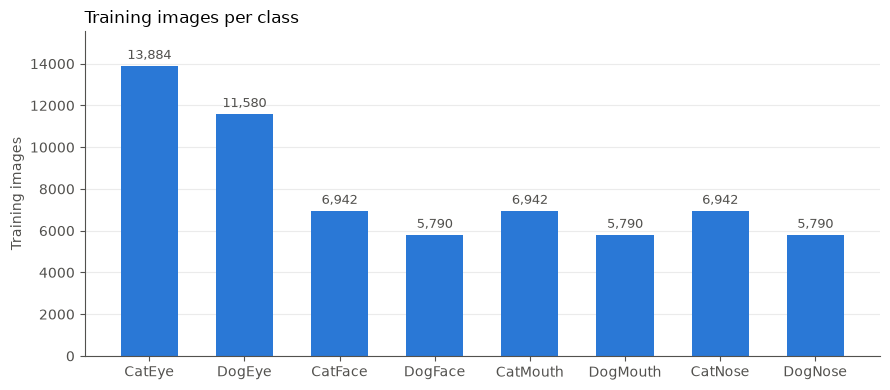

In [5]:
class_counts = train_df["class"].value_counts().reindex(CLASSES).fillna(0).astype(int)
dist = pd.DataFrame({"count": class_counts, "percent": (100 * class_counts / class_counts.sum()).round(2)})
display(dist)
print(f"Largest / smallest class ratio: {class_counts.max() / max(class_counts.min(), 1):.2f}")

# The 8 labels are really two factors: animal (Cat/Dog) x facial feature (Eye/Face/Mouth/Nose).
train_df["animal"] = train_df["class"].str.extract(r"^(Cat|Dog)", expand=False)
train_df["feature"] = train_df["class"].str.replace(r"^(Cat|Dog)", "", regex=True)
by_factor = pd.crosstab(train_df["feature"], train_df["animal"], margins=True, margins_name="Total")
display(by_factor)

dist.to_csv(OUT_DIR / "class_counts.csv")
by_factor.to_csv(OUT_DIR / "class_counts_animal_x_feature.csv")

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(dist.index, dist["count"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{c:,}" for c in dist["count"]], padding=3, fontsize=9, color=INK2)
ax.set_ylabel("Training images")
ax.set_title("Training images per class", loc="left")
ax.grid(axis="x", visible=False)
ax.margins(y=0.12)
fig.tight_layout()
fig.savefig(OUT_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Your observations (class balance):** _write what you notice here in your own words_

## 4. Sample images from each class

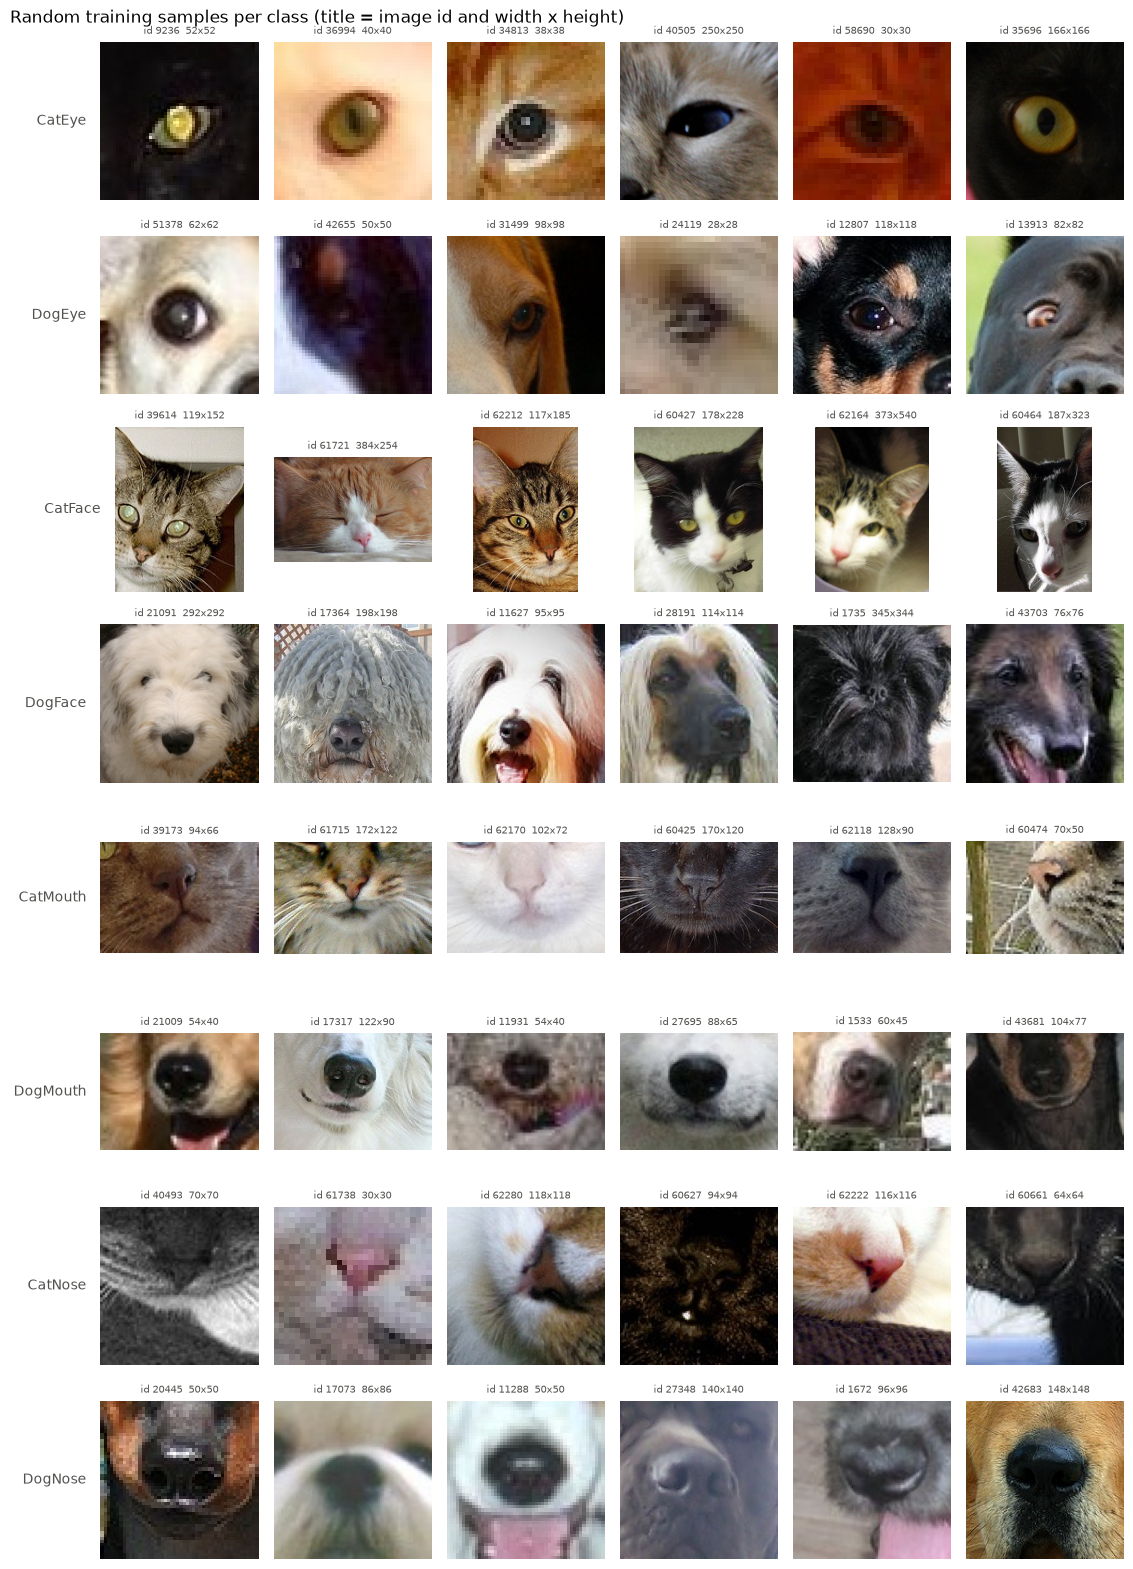

In [6]:
N_PER_CLASS = 6
fig, axes = plt.subplots(len(CLASSES), N_PER_CLASS, figsize=(N_PER_CLASS * 1.9, len(CLASSES) * 2.0))
for r, cls in enumerate(CLASSES):
    pool = train_df.loc[train_df["class"] == cls, ["image_id", "path"]]
    picks = pool.sample(min(N_PER_CLASS, len(pool)), random_state=CFG["seed"])
    for c in range(N_PER_CLASS):
        ax = axes[r, c]
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        if c < len(picks):
            row = picks.iloc[c]
            im = load_rgb(row["path"])
            if im is None:
                ax.text(0.5, 0.5, "unreadable", ha="center", va="center", fontsize=8, color=INK2)
                ax.set_title(f"id {row['image_id']}", fontsize=7, color=INK2)
            else:
                ax.imshow(im)
                ax.set_title(f"id {row['image_id']}  {im.size[0]}x{im.size[1]}", fontsize=7, color=INK2)
    axes[r, 0].set_ylabel(cls, fontsize=10, rotation=0, ha="right", va="center", labelpad=10)
fig.suptitle("Random training samples per class (title = image id and width x height)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(OUT_DIR / "samples_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

**Your observations (what the classes look like, anything confusing):** _write here_

## 5. Scan every image (train and test)

Each file is read **once** and we record:
- `width`, `height`, `mode` (RGB / L = greyscale / RGBA ...), file size
- `ok` — whether the file can be verified and fully decoded (False = corrupted)
- `md5` — hash of the raw bytes → finds byte-identical duplicates
- `dhash` — difference hash of a 9×8 greyscale thumbnail → the same picture saved at a different size or
  compression gets the same hash, so it also finds near-duplicates (used for the split in Part B)
- `blur` — variance of the Laplacian of the greyscale image. Low = few sharp edges = likely blurry.
  It also depends on image size and content, so it is used to *rank* images for a visual check, not as a hard rule.

In [7]:
def dhash_hex(img, size=8):
    g = np.asarray(img.convert("L").resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).flatten()        # is each pixel brighter than its left neighbour?
    return np.packbits(bits).tobytes().hex()

def inspect_image(path):
    rec = {"path": path, "file_kb": np.nan, "md5": None, "dhash": None, "ok": False,
           "width": np.nan, "height": np.nan, "mode": None, "blur": np.nan, "error": None}
    try:
        data = Path(path).read_bytes()
        rec["file_kb"] = len(data) / 1024
        rec["md5"] = hashlib.md5(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            im.verify()                      # structural integrity check
        with Image.open(io.BytesIO(data)) as im:
            im.load()                        # full decode (catches truncated files)
            rec["width"], rec["height"] = im.size
            rec["mode"] = im.mode
            rec["dhash"] = dhash_hex(im)
            gray = np.asarray(im.convert("L"), dtype=np.uint8)
        rec["blur"] = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        rec["ok"] = True
    except Exception as e:
        rec["error"] = f"{type(e).__name__}: {e}"
    return rec

scan_input = pd.concat([
    train_df[["image_id", "path", "class"]].assign(split="train"),
    test_df[["image_id", "path"]].assign(split="test", **{"class": None}),
], ignore_index=True)

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
    records = list(pool.map(inspect_image, scan_input["path"], chunksize=256))
stats = scan_input.merge(pd.DataFrame(records), on="path")
stats["aspect"] = stats["width"] / stats["height"]
stats.drop(columns=["path"]).to_csv(OUT_DIR / "image_stats.csv", index=False)
print(f"Scanned {len(stats):,} images in {time.time() - t0:.0f}s. Per-image table: {OUT_DIR / 'image_stats.csv'}")

# Attach the scan results to the training table (used in Part B).
scan_cols = ["path", "ok", "md5", "dhash", "width", "height", "mode", "blur", "error"]
train_df = train_df.merge(stats.loc[stats["split"] == "train", scan_cols], on="path", how="left")

Scanned 93,103 images in 36s. Per-image table: outputs\image_stats.csv


### 5a. Image sizes and colour modes

Colour modes by split:


split,test,train
mode,,
RGB,29443,63660


Width / height / aspect / file size summary by split:


split              test     train
width   count  29443.00  63660.00
        mean     113.55    113.10
        std      100.75     98.49
        min        8.00      4.00
        25%       53.00     54.00
        50%       82.00     84.00
        75%      140.00    138.00
        max     1832.00   2219.00
height  count  29443.00  63660.00
        mean     109.70    109.74
        std      103.68    101.91
        min        9.00      4.00
        25%       50.00     50.00
        50%       80.00     80.00
        75%      128.00    130.00
        max     1978.00   2219.00
aspect  count  29443.00  63660.00
        mean       1.08      1.06
        std        0.23      0.19
        min        0.30      0.40
        25%        0.99      1.00
        50%        1.00      1.00
        75%        1.20      1.00
        max        4.44     10.00
file_kb count  29443.00  63660.00
        mean      10.69     10.61
        std       25.92     24.06
        min        0.68      0.64
        25%        2.14      2.16
        50%        4.11      4.23
        75%        9.45      9.63
        max     1175.96   1233.08

Number of distinct (width, height) combinations: {'test': 7786, 'train': 7861}
Most common sizes (train + test):


,width,height,images
0,40,40,1565
1,50,50,1295
2,60,60,1213
3,48,48,1198
4,30,30,1123
5,38,38,1114
6,42,42,1113
7,44,44,1099
8,36,36,1090
9,80,80,1063


Median width x height per class (train):


,width,height
class,,
CatEye,68.0,68.0
DogEye,62.0,62.0
CatFace,182.0,215.0
DogFace,155.0,155.0
CatMouth,114.0,80.0
DogMouth,104.0,77.0
CatNose,68.0,68.0
DogNose,62.0,62.0


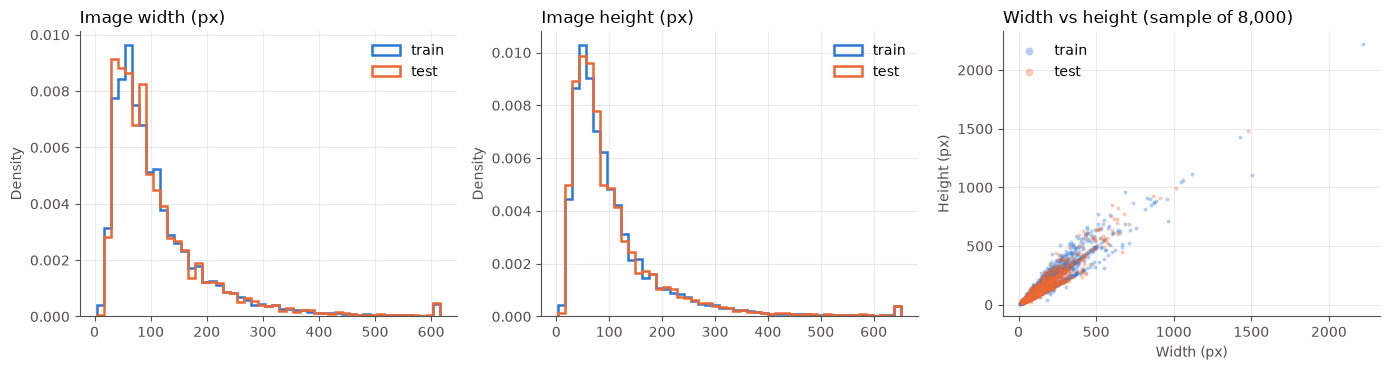

In [8]:
ok_stats = stats[stats["ok"]]
print("Colour modes by split:")
display(pd.crosstab(ok_stats["mode"], ok_stats["split"]))

print("Width / height / aspect / file size summary by split:")
display(ok_stats.groupby("split")[["width", "height", "aspect", "file_kb"]].describe().T.round(2))

n_sizes = {s: g[["width", "height"]].drop_duplicates().shape[0] for s, g in ok_stats.groupby("split")}
print("Number of distinct (width, height) combinations:", n_sizes)
top_sizes = (ok_stats.groupby(["width", "height"]).size().sort_values(ascending=False)
             .head(10).rename("images").reset_index())
print("Most common sizes (train + test):")
display(top_sizes)

print("Median width x height per class (train):")
size_by_class = ok_stats[ok_stats["split"] == "train"].groupby("class")[["width", "height"]].median().reindex(CLASSES)
display(size_by_class)
size_by_class.to_csv(OUT_DIR / "median_size_per_class.csv")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes[:2], ["width", "height"]):
    hi = ok_stats[col].quantile(0.995)  # clip extreme outliers so the shape is readable
    bins = np.linspace(ok_stats[col].min(), hi, 50)
    for split, color in [("train", BLUE), ("test", ORANGE)]:
        ax.hist(ok_stats.loc[ok_stats["split"] == split, col].clip(upper=hi), bins=bins, color=color,
                histtype="step", linewidth=1.8, label=split, density=True)
    ax.set_title(f"Image {col} (px)", loc="left")
    ax.set_ylabel("Density")
    ax.legend(frameon=False)
sample_pts = ok_stats.sample(min(len(ok_stats), 8000), random_state=CFG["seed"])
for split, color in [("train", BLUE), ("test", ORANGE)]:
    s = sample_pts[sample_pts["split"] == split]
    axes[2].scatter(s["width"], s["height"], s=8, alpha=0.35, color=color, label=split, linewidths=0)
axes[2].set_xlabel("Width (px)"); axes[2].set_ylabel("Height (px)")
axes[2].set_title("Width vs height (sample of 8,000)", loc="left")
axes[2].legend(frameon=False, markerscale=2)
fig.tight_layout()
fig.savefig(OUT_DIR / "image_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

**Your observations (sizes, modes, what input size might suit the model):** _write here_

### 5b. Corrupted / unreadable files

In [9]:
bad = stats[~stats["ok"]]
print(f"Unreadable files: {len(bad)} (train {int((bad['split'] == 'train').sum())}, test {int((bad['split'] == 'test').sum())})")
if len(bad):
    display(bad[["split", "image_id", "class", "error"]].head(20))
    bad[["split", "image_id", "class", "error"]].to_csv(OUT_DIR / "corrupted_files.csv", index=False)

Unreadable files: 0 (train 0, test 0)


### 5c. Exact duplicate files

Train images that have an exact duplicate in train      30
  ...distinct duplicated train files                    15
  ...duplicate groups with conflicting labels           0
Test images that have an exact duplicate in test        124
Distinct files present in both train and test           0


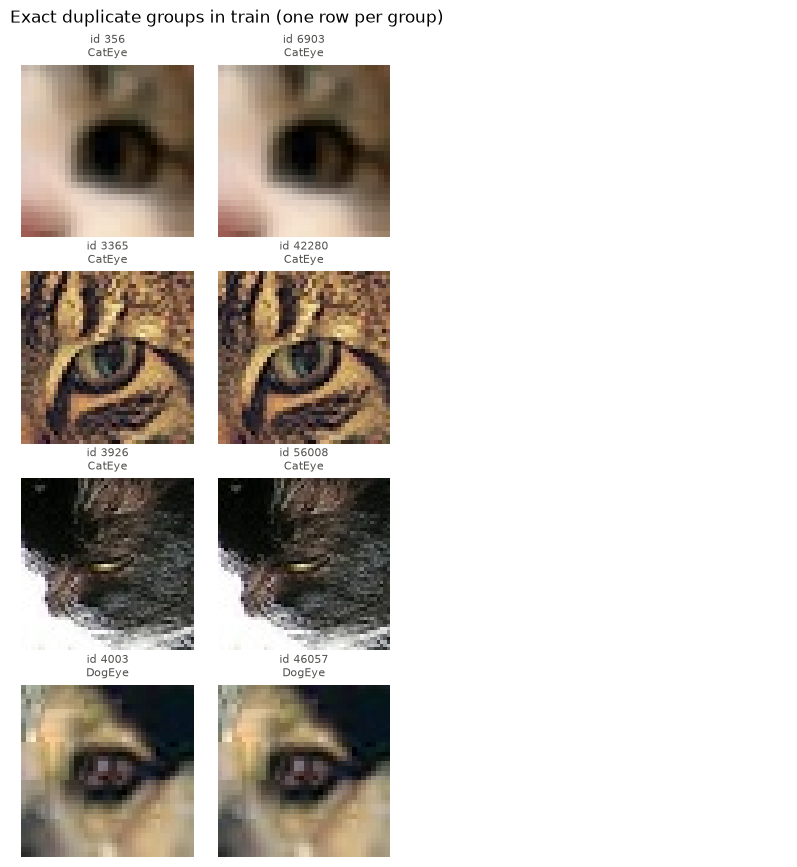

In [10]:
good = stats[stats["ok"]].copy()
dup_groups = good.groupby("md5").filter(lambda g: len(g) > 1)

train_dup = good[good["split"] == "train"]
train_dup = train_dup[train_dup.duplicated("md5", keep=False)]
test_dup = good[good["split"] == "test"]
test_dup = test_dup[test_dup.duplicated("md5", keep=False)]

# Duplicates inside train whose copies carry different labels (label noise).
conflicts_md5 = train_dup.groupby("md5").filter(lambda g: g["class"].nunique() > 1)

# Files that appear in both train and test. Counted ONLY as a data-quality / leakage check for the report.
# Never copy train labels onto these test ids - inferring hidden test labels breaks the competition rules.
cross = set(good.loc[good["split"] == "train", "md5"]) & set(good.loc[good["split"] == "test", "md5"])

dup_summary = {
    "Train images that have an exact duplicate in train": len(train_dup),
    "  ...distinct duplicated train files": train_dup["md5"].nunique(),
    "  ...duplicate groups with conflicting labels": conflicts_md5["md5"].nunique(),
    "Test images that have an exact duplicate in test": len(test_dup),
    "Distinct files present in both train and test": len(cross),
}
for k, v in dup_summary.items():
    print(f"{k:55s} {v}")

dup_groups[["split", "image_id", "class", "md5"]].sort_values(["md5", "split"]).to_csv(
    OUT_DIR / "exact_duplicates.csv", index=False)

# Show up to 4 duplicate groups from train (conflicting-label groups first).
show = list(conflicts_md5["md5"].unique()[:4])
show += [m for m in train_dup["md5"].unique() if m not in show][: 4 - len(show)]
if show:
    fig, axes = plt.subplots(len(show), 4, figsize=(8, 2.2 * len(show)), squeeze=False)
    for r, m in enumerate(show):
        grp = train_dup[train_dup["md5"] == m].head(4)
        for c in range(4):
            ax = axes[r, c]; ax.axis("off")
            if c < len(grp):
                row = grp.iloc[c]
                ax.imshow(load_rgb(row["path"]))
                ax.set_title(f"id {row['image_id']}\n{row['class']}", fontsize=8, color=INK2)
    fig.suptitle("Exact duplicate groups in train (one row per group)", x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "duplicate_examples.png", dpi=150, bbox_inches="tight")
    plt.show()

**Your observations (duplicates, label conflicts):** _write here_

### 5d. Blur check

Blur score (variance of Laplacian) by class - lower = blurrier:


,count,mean,std,min,5%,50%,max
class,,,,,,,
CatEye,13884.0,3656.0,4548.7,4.2,217.4,2166.1,59231.1
DogEye,11580.0,1605.5,2051.2,5.9,104.8,919.6,31419.3
CatFace,6942.0,2908.2,3274.4,4.9,222.9,1904.9,50453.9
DogFace,5790.0,1512.8,1755.8,6.3,117.4,923.2,17012.8
CatMouth,6942.0,3095.9,3764.2,3.7,160.1,1841.6,50974.6
DogMouth,5790.0,1674.1,1952.1,4.9,123.7,1017.5,20344.7
CatNose,6942.0,2426.6,3171.1,3.6,117.7,1401.4,53377.1
DogNose,5790.0,1770.3,2069.6,5.1,127.0,1098.4,24233.7


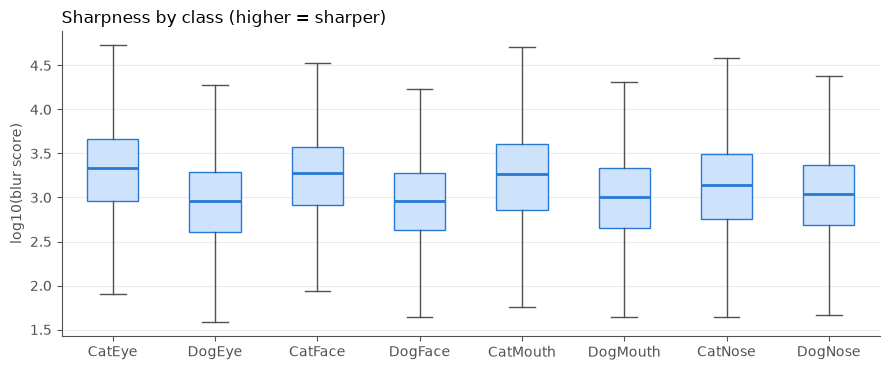

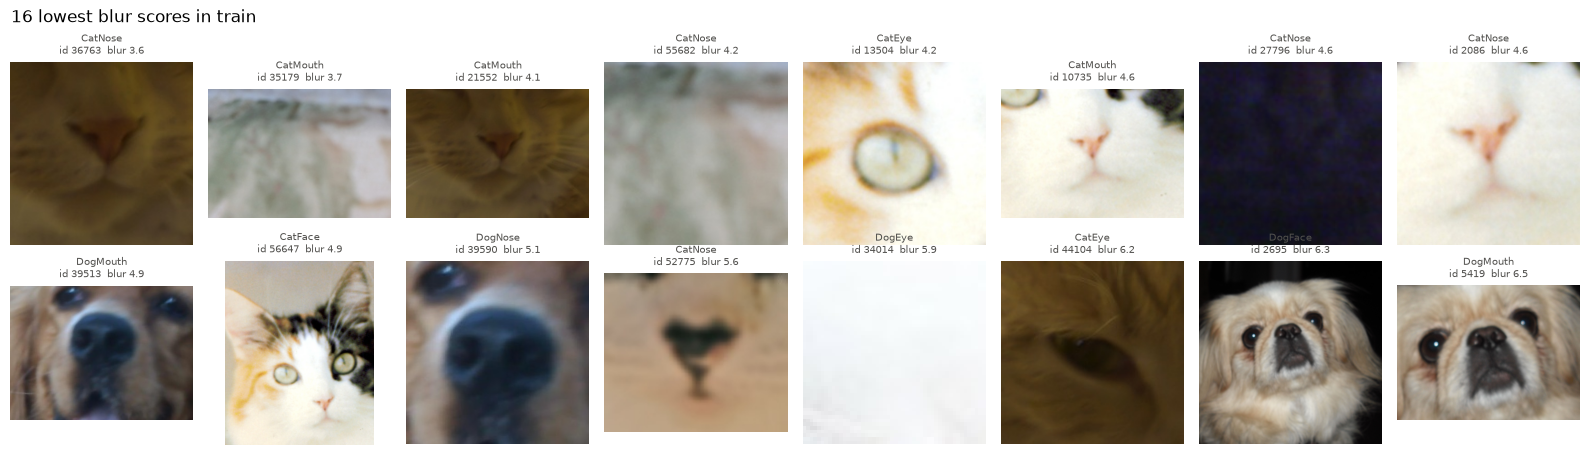

In [11]:
train_ok = stats[(stats["split"] == "train") & stats["ok"]].copy()

print("Blur score (variance of Laplacian) by class - lower = blurrier:")
blur_by_class = train_ok.groupby("class")["blur"].describe(percentiles=[0.05, 0.5]).reindex(CLASSES).round(1)
display(blur_by_class)
blur_by_class.to_csv(OUT_DIR / "blur_by_class.csv")

fig, ax = plt.subplots(figsize=(9, 3.8))
data = [np.log10(train_ok.loc[train_ok["class"] == c, "blur"].clip(lower=1e-3)) for c in CLASSES]
ax.boxplot(data, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
ax.set_xticks(range(1, len(CLASSES) + 1))
ax.set_xticklabels(CLASSES)  # set separately: boxplot's labels argument was renamed across matplotlib versions
ax.set_ylabel("log10(blur score)")
ax.set_title("Sharpness by class (higher = sharper)", loc="left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "blur_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

# The 16 lowest-scoring training images, for a visual check.
low = train_ok.nsmallest(16, "blur")
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, (_, row) in zip(axes.ravel(), low.iterrows()):
    ax.imshow(load_rgb(row["path"]))
    ax.set_title(f"{row['class']}\nid {row['image_id']}  blur {row['blur']:.1f}", fontsize=7, color=INK2)
    ax.axis("off")
for ax in axes.ravel()[len(low):]:
    ax.axis("off")
fig.suptitle("16 lowest blur scores in train", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(OUT_DIR / "blurriest_train_images.png", dpi=150, bbox_inches="tight")
plt.show()

**Your observations (are low-score images actually blurry? any classes affected more?):** _write here_

**How the data will be used (write your own):** training / validation / Kaggle submission, and anything above
that affects that plan.

# Part B — Task 2: Preprocessing and data pipeline

## 6. Encode class labels

The class names are mapped to integers with a **fixed, explicit order** (`CLASSES` in the setup cell), not
whatever order the data happens to appear in. The same mapping is saved to `class_mapping.json` and is used
later to turn predicted integers back into class names for the Kaggle submission.

In [12]:
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

unknown = sorted(set(train_df["class"]) - set(CLASSES))
assert not unknown, f"Unexpected class names in train_labels.csv: {unknown}"
train_df["label"] = train_df["class"].map(CLASS_TO_IDX).astype(int)

display(pd.DataFrame({"class": CLASSES, "label": [CLASS_TO_IDX[c] for c in CLASSES]}).set_index("label"))

with open(OUT_DIR / "class_mapping.json", "w") as f:
    json.dump({"class_to_idx": CLASS_TO_IDX, "idx_to_class": {str(k): v for k, v in IDX_TO_CLASS.items()}}, f, indent=2)

,class
label,
0,CatEye
1,DogEye
2,CatFace
3,DogFace
4,CatMouth
5,DogMouth
6,CatNose
7,DogNose


## 7. Clean the training data

Using the scan from section 5:
- **corrupted** files are removed (they cannot be loaded);
- **duplicate groups with conflicting labels** are removed (we cannot know which label is correct);
- **extra byte-identical copies** with the same label are removed (one copy is kept).

Each image is also given a **group** = its dHash (near-duplicates share a group). Images with a "flat" hash
(no brightness changes at all) use their md5 instead, so unrelated plain images are not grouped together.
Every removed image is logged with its reason in `removed_training_images.csv`.

In [13]:
FLAT_HASH = "0" * 16
train_df["group"] = np.where(
    train_df["dhash"].isna() | (train_df["dhash"] == FLAT_HASH),
    "md5_" + train_df["md5"].fillna(train_df["image_id"].astype(str)),
    "dh_" + train_df["dhash"].fillna(""),
)

removed = []   # every image dropped from training, with the reason

# 7a. Corrupted files
corrupt_train = train_df[~train_df["ok"].fillna(False).astype(bool)]
print(f"Corrupted / unreadable training files: {len(corrupt_train)}")
if CFG["drop_corrupted"] and len(corrupt_train):
    removed.append(corrupt_train.assign(reason="corrupted"))
    train_df = train_df.drop(index=corrupt_train.index)

# 7b. Duplicate groups (exact or near) whose members carry different labels
labels_per_group = train_df.groupby("group")["class"].nunique()
conflict_groups = labels_per_group[labels_per_group > 1].index
conflicts = train_df[train_df["group"].isin(conflict_groups)]
print(f"Duplicate groups with conflicting labels: {len(conflict_groups)}  ({len(conflicts)} images)")
if len(conflicts):
    display(conflicts.sort_values("group")[["image_id", "class", "group"]].head(20))
if CFG["drop_label_conflicts"] and len(conflicts):
    removed.append(conflicts.assign(reason="duplicate with conflicting label"))
    train_df = train_df[~train_df["group"].isin(conflict_groups)]

# 7c. Byte-identical copies with the same label: keep the first one
copies = train_df[train_df.duplicated(["md5", "class"], keep="first")]
print(f"Extra byte-identical copies (same label): {len(copies)}")
if CFG["dedupe_exact_copies"] and len(copies):
    removed.append(copies.assign(reason="exact duplicate copy"))
    train_df = train_df.drop(index=copies.index)

removed_df = (pd.concat(removed, ignore_index=True) if removed
              else pd.DataFrame(columns=["image_id", "class", "reason", "error"]))
removed_df[["image_id", "class", "reason", "error"]].to_csv(OUT_DIR / "removed_training_images.csv", index=False)

train_df = train_df.reset_index(drop=True)
group_sizes = train_df["group"].value_counts()
print(f"\nImages kept for training/validation: {len(train_df):,}  (removed {len(removed_df):,})")
print(f"Groups: {len(group_sizes):,}   groups with >1 image: {(group_sizes > 1).sum():,}   largest group: {group_sizes.max()}")
if len(removed_df):
    display(removed_df["reason"].value_counts().rename("images removed"))

Corrupted / unreadable training files: 0
Duplicate groups with conflicting labels: 0  (0 images)
Extra byte-identical copies (same label): 15

Images kept for training/validation: 63,645  (removed 15)
Groups: 63,613   groups with >1 image: 32   largest group: 2


reason
exact duplicate copy    15
Name: images removed, dtype: int64

Near-duplicate groups (different bytes, same dHash): 32


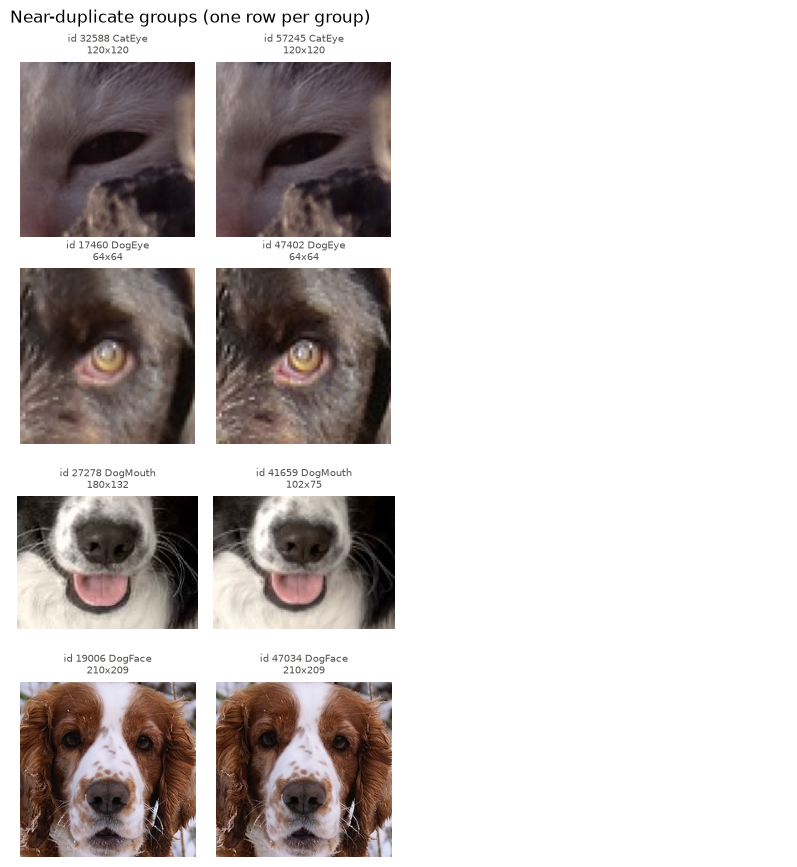

In [14]:
# Visual check of near-duplicate groups (same dHash, different files). If these do NOT look like the same
# picture, the hash is grouping too aggressively.
near = train_df[train_df["group"].str.startswith("dh_")]
near = near[near.groupby("group")["md5"].transform("nunique") > 1]
print(f"Near-duplicate groups (different bytes, same dHash): {near['group'].nunique()}")
show_groups = (near["group"].drop_duplicates().sample(min(4, near["group"].nunique()), random_state=CFG["seed"]).tolist()
               if len(near) else [])

if show_groups:
    fig, axes = plt.subplots(len(show_groups), 4, figsize=(8, 2.2 * len(show_groups)), squeeze=False)
    for r, g in enumerate(show_groups):
        grp = near[near["group"] == g].head(4)
        for c in range(4):
            ax = axes[r, c]; ax.axis("off")
            if c < len(grp):
                row = grp.iloc[c]
                ax.imshow(load_rgb(row["path"]))
                ax.set_title(f"id {row['image_id']} {row['class']}\n{int(row['width'])}x{int(row['height'])}",
                             fontsize=7, color=INK2)
    fig.suptitle("Near-duplicate groups (one row per group)", x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "near_duplicate_groups.png", dpi=150, bbox_inches="tight")
    plt.show()

## 8. Train / validation split

`StratifiedGroupKFold` splits the cleaned data into `round(1 / val_fraction)` folds:
- **stratified** → every fold has (almost) the same class proportions as the full dataset;
- **grouped** → all images in one hash group go to the same fold, so the same or a near-identical image
  can never be in training and validation at the same time.

Fold 0 is the validation set. Every image's fold number is saved, so the other folds can be used later for
cross-validation without re-running this notebook. The test images are never part of this split.

What this grouping does **not** catch: different crops that come from the same original photo
(for example an eye crop and the face crop of the same animal) have different hashes, so they can still be
split across train and validation. The data has no id that links crops to their source photo.

**Your justification (write your own):** _why this split strategy and validation size_

Assigned 7 folds in 14s
Train: 54,552   Validation: 9,093   (14.3% validation)
Leakage checks passed: no shared image ids, md5 hashes or dHash groups between train and validation.


,train,val,train %,val %
class,,,,
CatEye,11894,1983,21.80,21.81
DogEye,9922,1654,18.19,18.19
CatFace,5950,992,10.91,10.91
DogFace,4961,827,9.09,9.09
CatMouth,5949,992,10.91,10.91
DogMouth,4963,827,9.10,9.09
CatNose,5950,991,10.91,10.90
DogNose,4963,827,9.10,9.09


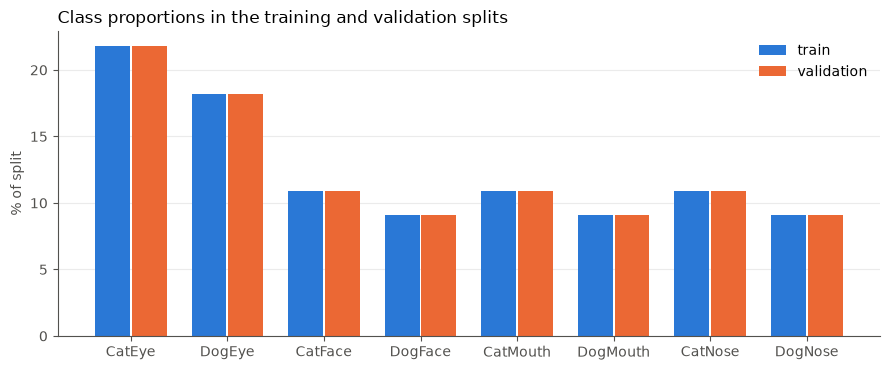

In [15]:
n_splits = max(2, round(1 / CFG["val_fraction"]))
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=CFG["seed"])
train_df["fold"] = -1
t0 = time.time()
for k, (_, idx) in enumerate(sgkf.split(train_df, train_df["label"], groups=train_df["group"])):
    train_df.loc[train_df.index[idx], "fold"] = k
print(f"Assigned {n_splits} folds in {time.time() - t0:.0f}s")
assert (train_df["fold"] >= 0).all()

VAL_FOLD = 0
train_split = train_df[train_df["fold"] != VAL_FOLD].reset_index(drop=True)
val_split = train_df[train_df["fold"] == VAL_FOLD].reset_index(drop=True)

# Leakage checks: no image, no identical file and no duplicate group on both sides.
assert set(train_split["image_id"]).isdisjoint(val_split["image_id"]), "image in both train and val"
assert set(train_split["group"]).isdisjoint(val_split["group"]), "duplicate group in both train and val"
assert set(train_split["md5"]).isdisjoint(val_split["md5"]), "identical file in both train and val"
print(f"Train: {len(train_split):,}   Validation: {len(val_split):,}   ({100 * len(val_split) / len(train_df):.1f}% validation)")
print("Leakage checks passed: no shared image ids, md5 hashes or dHash groups between train and validation.")

split_table = pd.DataFrame({
    "train": train_split["class"].value_counts(),
    "val": val_split["class"].value_counts(),
}).reindex(CLASSES)
split_table["train %"] = (100 * split_table["train"] / split_table["train"].sum()).round(2)
split_table["val %"] = (100 * split_table["val"] / split_table["val"].sum()).round(2)
display(split_table)
split_table.to_csv(OUT_DIR / "split_class_distribution.csv")

xpos = np.arange(len(CLASSES)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(xpos - w / 2, split_table["train %"], w * 0.95, color=BLUE, label="train")
ax.bar(xpos + w / 2, split_table["val %"], w * 0.95, color=ORANGE, label="validation")
ax.set_xticks(xpos); ax.set_xticklabels(CLASSES)
ax.set_ylabel("% of split")
ax.set_title("Class proportions in the training and validation splits", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "split_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### Class weights (computed on the training split only)

Weights `N / (num_classes × count_c)` for an optional weighted loss in the training notebook. They use the
**training split only**, so nothing about the validation set leaks into training.

In [16]:
train_counts = train_split["label"].value_counts().sort_index()
class_weights = (len(train_split) / (len(CLASSES) * train_counts)).round(4)
display(pd.DataFrame({"class": CLASSES, "train count": train_counts.values, "weight": class_weights.values}))
with open(OUT_DIR / "class_weights.json", "w") as f:
    json.dump({IDX_TO_CLASS[int(i)]: float(wt) for i, wt in class_weights.items()}, f, indent=2)

,class,train count,weight
0,CatEye,11894,0.5733
1,DogEye,9922,0.6873
2,CatFace,5950,1.1461
3,DogFace,4961,1.3745
4,CatMouth,5949,1.1462
5,DogMouth,4963,1.3740
6,CatNose,5950,1.1461
7,DogNose,4963,1.3740


## 9. Transforms, Dataset and DataLoaders

**Resize** — images come in many sizes and shapes. With `resize_mode="pad"` each image is scaled so its
longer side equals `img_size` (aspect ratio kept), then padded to a square with the ImageNet mean colour
(which becomes ~0 after normalisation). With `"stretch"` it is resized straight to a square.

**Normalise** — `ToTensor()` rescales pixels from 0–255 to 0–1, then `Normalize(mean, std)` standardises each
channel.

**Augment (training only)** — random horizontal flip, small rotation / shift / zoom, and mild colour jitter.
No vertical flips (faces are upright in real photos).

**Consistency** — validation and test images use the *same* `eval_tf` (resize + normalise only, no randomness),
built by the same function as the training transform.

**Your justification (write your own):** _input size, pad vs stretch, which augmentations and why_

In [17]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

MEAN_RGB = tuple(int(round(m * 255)) for m in CFG["mean"])   # padding colour = ImageNet mean

class ResizePad:
    # Resize so the longer side equals `size` (keeps aspect ratio), then pad to a size x size square.
    def __init__(self, size, fill=MEAN_RGB):
        self.size, self.fill = size, fill

    def __call__(self, img):
        w, h = img.size
        scale = self.size / max(w, h)
        nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
        img = img.resize((nw, nh), Image.BICUBIC)
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        canvas.paste(img, ((self.size - nw) // 2, (self.size - nh) // 2))
        return canvas

    def __repr__(self):
        return f"ResizePad(size={self.size})"

def build_transforms(cfg, train):
    size = cfg["img_size"]
    if cfg["resize_mode"] == "pad":
        resize = ResizePad(size)
    else:
        resize = T.Resize((size, size), interpolation=T.InterpolationMode.BICUBIC)
    steps = [resize]
    if train:
        steps += [
            T.RandomHorizontalFlip(p=0.5),
            T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1), fill=MEAN_RGB),
            T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
        ]
    steps += [T.ToTensor(), T.Normalize(cfg["mean"], cfg["std"])]
    return T.Compose(steps)

train_tf = build_transforms(CFG, train=True)
eval_tf = build_transforms(CFG, train=False)    # used for BOTH validation and test
print("Train transform:\n", train_tf, "\n\nValidation / test transform:\n", eval_tf)

Train transform:
 Compose(
    ResizePad(size=224)
    RandomHorizontalFlip(p=0.5)
    RandomAffine(degrees=[-10.0, 10.0], translate=(0.05, 0.05), scale=(0.9, 1.1), fill=(124, 116, 104))
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.02, 0.02))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
) 

Validation / test transform:
 Compose(
    ResizePad(size=224)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [18]:
class FacialFeatureDataset(Dataset):
    # Returns (image_tensor, label) for labelled data, or (image_tensor, image_id) for the test set.
    def __init__(self, df, transform, labelled=True, img_size=CFG["img_size"]):
        self.paths = df["path"].astype(str).tolist()
        self.ids = df["image_id"].astype(int).tolist()
        self.labels = df["label"].astype(int).tolist() if labelled else None
        self.transform = transform
        self.img_size = img_size

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        try:
            with Image.open(self.paths[i]) as im:
                img = im.convert("RGB")             # handles greyscale, RGBA and palette images
        except Exception:
            # Only possible for test images (corrupted training files were removed in section 7).
            # A blank image still gets a prediction, so the submission keeps every test id.
            img = Image.new("RGB", (self.img_size, self.img_size), MEAN_RGB)
        x = self.transform(img)
        target = self.ids[i] if self.labels is None else self.labels[i]
        return x, target

def seed_worker(worker_id):
    # Gives every DataLoader worker its own reproducible random seed (for the random augmentations).
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

def make_loader(ds, shuffle, batch_size, seed=CFG["seed"]):
    g = torch.Generator()
    g.manual_seed(seed)
    nw = CFG["num_workers"]
    return DataLoader(
        ds, batch_size=batch_size, shuffle=shuffle, drop_last=shuffle,
        num_workers=nw, pin_memory=torch.cuda.is_available(),
        persistent_workers=nw > 0, worker_init_fn=seed_worker, generator=g,
    )

assert len(test_df) == len(test_df_all), "Some test ids have no image file - the submission would be incomplete."

torch.manual_seed(CFG["seed"])
train_ds = FacialFeatureDataset(train_split, train_tf)
val_ds = FacialFeatureDataset(val_split, eval_tf)
test_ds = FacialFeatureDataset(test_df, eval_tf, labelled=False)

train_loader = make_loader(train_ds, shuffle=True, batch_size=CFG["batch_size"])
val_loader = make_loader(val_ds, shuffle=False, batch_size=CFG["batch_size"] * 2)
test_loader = make_loader(test_ds, shuffle=False, batch_size=CFG["batch_size"] * 2)

print(f"train: {len(train_ds):,} images, {len(train_loader)} batches")
print(f"val:   {len(val_ds):,} images, {len(val_loader)} batches")
print(f"test:  {len(test_ds):,} images, {len(test_loader)} batches")

train: 54,552 images, 852 batches
val:   9,093 images, 72 batches
test:  29,443 images, 231 batches


## 10. Sanity and leakage checks

In [19]:
def denorm(x):
    # Undo Normalize so a tensor can be shown as an image.
    mean = torch.tensor(CFG["mean"]).view(3, 1, 1)
    std = torch.tensor(CFG["std"]).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

# One batch from each loader: shape, dtype, value range and labels.
for name, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    xb, yb = next(iter(loader))
    print(f"{name:5s} x {tuple(xb.shape)} {xb.dtype}  min {xb.min():.2f}  max {xb.max():.2f}  "
          f"mean {xb.mean():.2f}  std {xb.std():.2f} | target {tuple(yb.shape)} {yb.dtype}")
    assert xb.shape[1:] == (3, CFG["img_size"], CFG["img_size"])
    if name != "test":
        assert int(yb.min()) >= 0 and int(yb.max()) < len(CLASSES)

train x (64, 3, 224, 224) torch.float32  min -2.12  max 2.64  mean -0.15  std 1.08 | target (64,) torch.int64
val   x (128, 3, 224, 224) torch.float32  min -2.12  max 2.64  mean -0.09  std 1.15 | target (128,) torch.int64
test  x (128, 3, 224, 224) torch.float32  min -2.12  max 2.64  mean -0.02  std 1.08 | target (128,) torch.int64


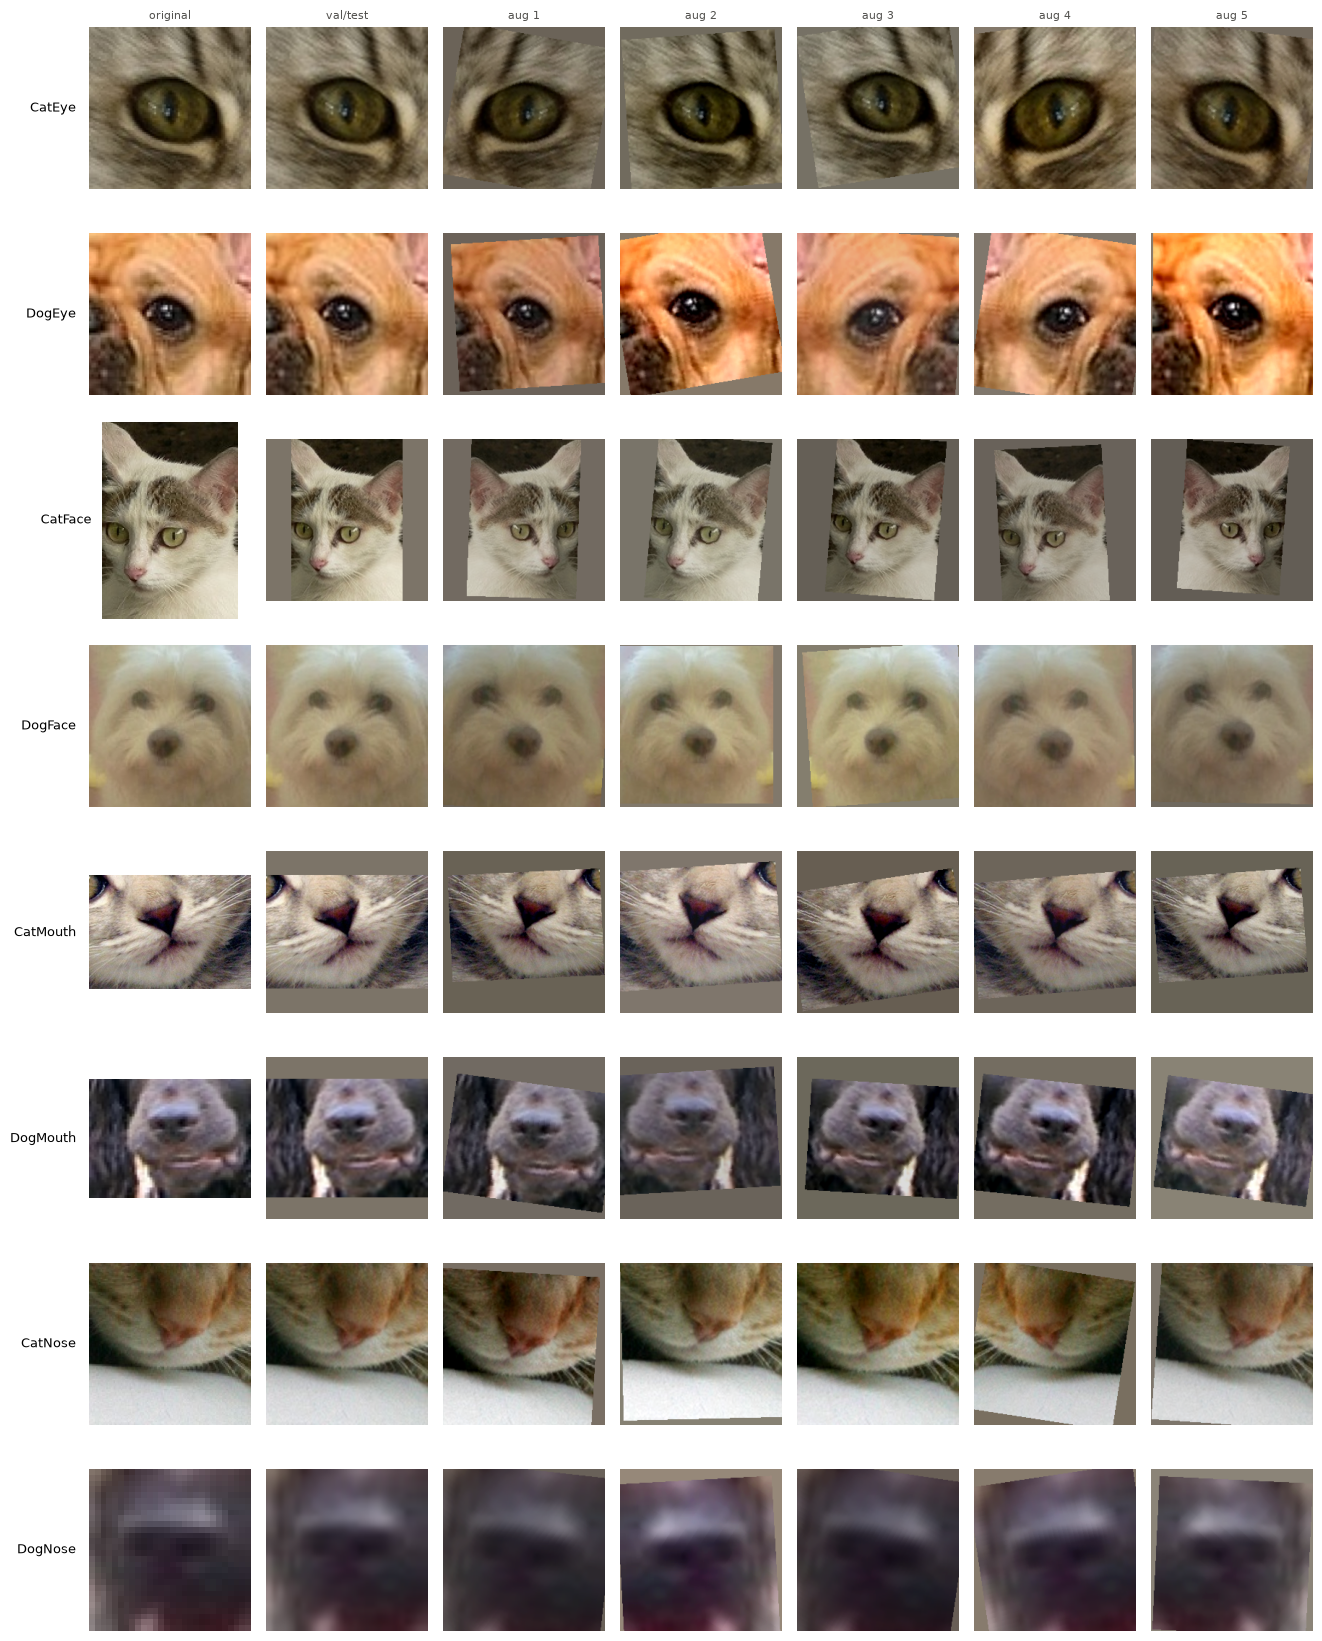

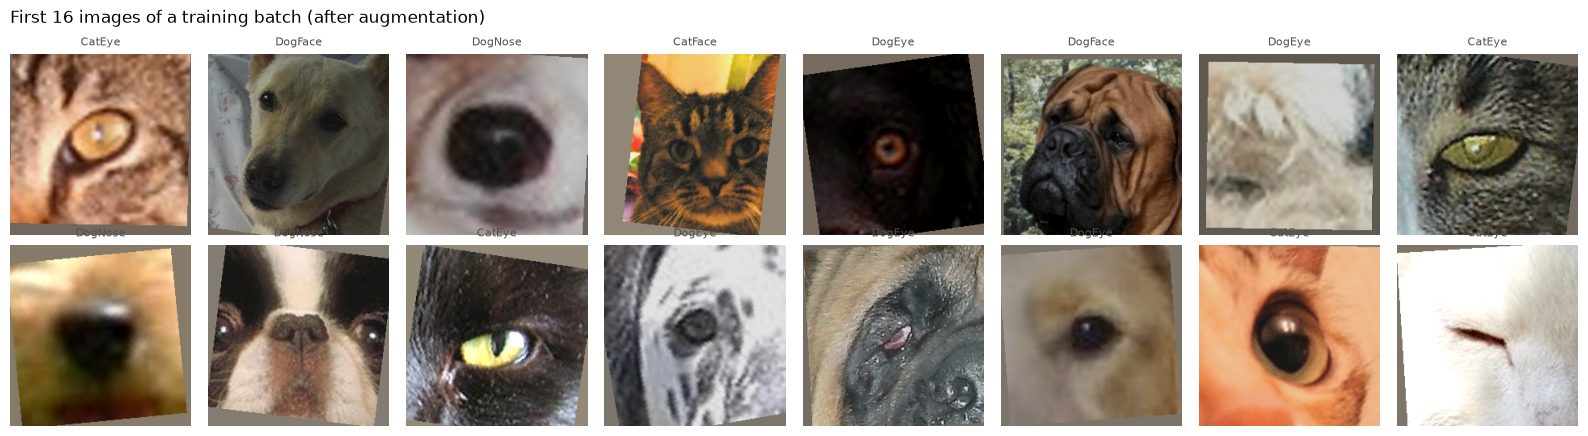

In [20]:
# Augmentation preview: one validation image per class. Column 1 = original file, column 2 = what validation/test
# images look like after preprocessing, columns 3+ = random training augmentations of the same image.
N_AUG = 5
rows = val_split.groupby("class").head(1).set_index("class").reindex(CLASSES).dropna(subset=["path"])
fig, axes = plt.subplots(len(rows), N_AUG + 2, figsize=(1.9 * (N_AUG + 2), 2.1 * len(rows)), squeeze=False)
for r, (cls, row) in enumerate(rows.iterrows()):
    img = load_rgb(row["path"])
    panels = [("original", np.asarray(img)), ("val/test", denorm(eval_tf(img)))]
    panels += [(f"aug {k + 1}", denorm(train_tf(img))) for k in range(N_AUG)]
    for c, (title, arr) in enumerate(panels):
        axes[r, c].imshow(arr); axes[r, c].axis("off")
        axes[r, c].set_title(title if r == 0 else "", fontsize=8, color=INK2)
    axes[r, 0].text(-0.08, 0.5, cls, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "augmentation_preview.png", dpi=150, bbox_inches="tight")
plt.show()

# A real training batch exactly as the model will receive it.
xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, x, y in zip(axes.ravel(), xb[:16], yb[:16]):
    ax.imshow(denorm(x)); ax.axis("off")
    ax.set_title(IDX_TO_CLASS[int(y)], fontsize=8, color=INK2)
fig.suptitle("First 16 images of a training batch (after augmentation)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(OUT_DIR / "train_batch_preview.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
# Loading speed: if this is slow, the GPU will sit idle during training waiting for data.
n_batches = min(30, len(train_loader))
t0 = time.time()
for i, (xb, yb) in enumerate(train_loader):
    if i + 1 >= n_batches:
        break
elapsed = time.time() - t0
print(f"{n_batches} training batches in {elapsed:.1f}s  ->  {n_batches * CFG['batch_size'] / elapsed:,.0f} images/s "
      f"with {CFG['num_workers']} workers")

30 training batches in 7.8s  ->  245 images/s with 0 workers


In [22]:
# Final leakage / consistency checklist.
leak_checks = {
    "No image id in both train and validation": set(train_split["image_id"]).isdisjoint(val_split["image_id"]),
    "No duplicate group in both train and validation": set(train_split["group"]).isdisjoint(val_split["group"]),
    "Test images are not used for training or validation": len(set(test_df["path"].astype(str))
                                                               & set(train_df["path"].astype(str))) == 0,
    "Validation and test share the same transform object": val_ds.transform is test_ds.transform,
    "Validation/test transform has no random steps": not any("Random" in type(t).__name__ or "Jitter" in type(t).__name__
                                                             for t in eval_tf.transforms),
    "Normalisation uses fixed constants (not fitted on any split)": True,
    "Class weights computed from the training split only": int(train_counts.sum()) == len(train_split),
    "Every test id has an image": len(test_ds) == len(sample_sub),
}
for k, v in leak_checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(leak_checks.values())

PASS  No image id in both train and validation
PASS  No duplicate group in both train and validation
PASS  Test images are not used for training or validation
PASS  Validation and test share the same transform object
PASS  Validation/test transform has no random steps
PASS  Normalisation uses fixed constants (not fitted on any split)
PASS  Class weights computed from the training split only
PASS  Every test id has an image


## 11. Save everything the training notebook needs

In [23]:
def rel(p):
    return str(Path(p).relative_to(DATA_ROOT))

cols = ["image_id", "class", "label", "fold", "group", "md5"]
splits_out = train_df[cols].assign(relpath=train_df["path"].map(rel), is_val=train_df["fold"] == VAL_FOLD)
splits_out.to_csv(OUT_DIR / "splits.csv", index=False)

with open(OUT_DIR / "preprocessing_config.json", "w") as f:
    json.dump({**CFG, "classes": CLASSES, "val_fold": VAL_FOLD, "n_splits": n_splits,
               "n_train": len(train_split), "n_val": len(val_split), "n_test": len(test_df),
               "train_transform": str(train_tf), "eval_transform": str(eval_tf)}, f, indent=2)

for f in sorted(OUT_DIR.iterdir()):
    print(f"{f.name:36s} {f.stat().st_size / 1024:8.1f} KB")

augmentation_preview.png               3634.8 KB
best_convnext_tiny.pt                108761.9 KB
blur_by_class.csv                         0.5 KB
blur_by_class.png                        34.9 KB
blurriest_train_images.png             1092.7 KB
class_counts.csv                          0.2 KB
class_counts_animal_x_feature.csv         0.1 KB
class_distribution.png                   42.7 KB
class_mapping.json                        0.4 KB
class_weights.json                        0.2 KB
classification_report_convnext_tiny.csv      0.7 KB
confusion_matrix_convnext_tiny.png       70.3 KB
duplicate_examples.png                   76.2 KB
exact_duplicates.csv                      7.1 KB
history_convnext_tiny.csv                 0.3 KB
image_sizes.png                          83.9 KB
image_stats.csv                       11377.4 KB
learning_curves_convnext_tiny.png        90.5 KB
median_size_per_class.csv                 0.2 KB
misclassified_convnext_tiny.png         768.5 KB
near_duplicate_gr

GPU: NVIDIA GeForce RTX 3060
Train 54,552 | Validation 9,093 | Test 29,443 images
convnext_tiny: 27.8 M parameters (6,152 in the new head)
New head: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=768, out_features=8, bias=True)
)
Input (8, 3, 224, 224) -> output (8, 8) | initial loss 2.01 (expected ~2.1)
  epoch 1 step 213/852  loss 1.2699  acc 0.6491  95 img/s
  epoch 1 step 426/852  loss 0.9044  acc 0.8153  109 img/s
  epoch 1 step 639/852  loss 0.7722  acc 0.8725  117 img/s
  epoch 1 step 852/852  loss 0.7048  acc 0.9014  121 img/s
Epoch  1/12  train_ce 0.3791 acc 0.9014 | val_ce 0.1191 acc 0.9872 f1 0.9874 | 8.1 min  <- best, saved
  peak GPU memory 4.4 GB
  estimated time for all epochs: 98 min
  epoch 2 step 213/852  loss 0.4951  acc 0.9897  140 img/s
  epoch 2 step 426/852  loss 0.4937  acc 0.9902  140 img/s
  epoch 2 step 639/852  loss 0.4919  acc 0.9909  140 img/s
  epoch 2 step 852/852  loss 0.4923  acc 0.9906  140 img/s
Epoch  2/12  train_ce 0.118

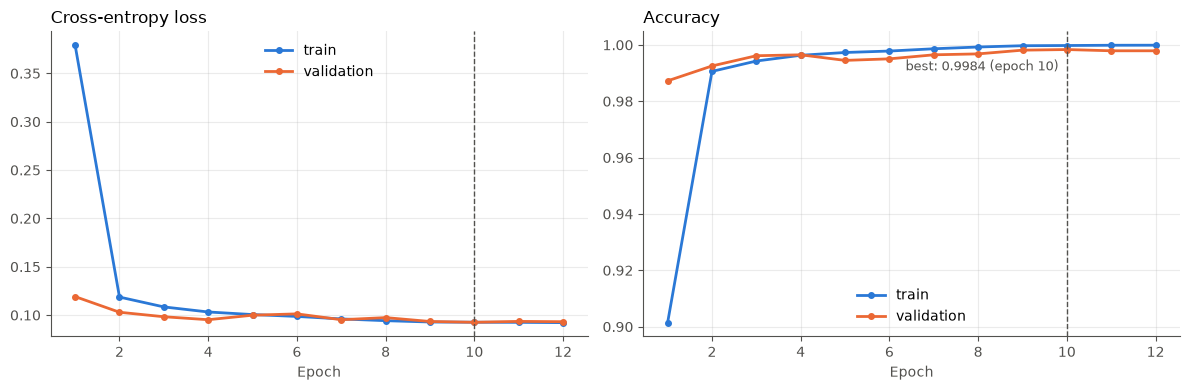

,epoch,lr_backbone,train_loss,train_ce,train_acc,val_ce,val_acc,val_macro_f1,epoch_time_s
0,1,0.0001,0.7048,0.3791,0.9014,0.1191,0.9872,0.9874,487.8644
1,2,0.0001,0.4923,0.1186,0.9906,0.1029,0.9925,0.9933,409.8716
2,3,0.0001,0.4826,0.1084,0.9943,0.0983,0.9962,0.9965,386.6077
3,4,0.0001,0.4780,0.1032,0.9963,0.0952,0.9965,0.9967,386.7939
4,5,0.0001,0.4755,0.1005,0.9973,0.0999,0.9945,0.9954,386.6620
5,6,0.0001,0.4738,0.0986,0.9978,0.1012,0.9951,0.9959,390.5304
6,7,0.0000,0.4715,0.0960,0.9986,0.0952,0.9965,0.9967,389.8208
7,8,0.0000,0.4698,0.0942,0.9992,0.0974,0.9968,0.9969,386.3401
8,9,0.0000,0.4686,0.0928,0.9997,0.0934,0.9981,0.9983,386.1704
9,10,0.0000,0.4684,0.0926,0.9998,0.0926,0.9984,0.9985,387.0332


Loaded best checkpoint from epoch 10


,accuracy,loss,macro_f1
no TTA,0.9984,0.0926,0.9985
TTA (flip),0.9980,0.0919,0.9982


,precision,recall,f1-score,support
CatEye,0.9985,0.9975,0.9980,1983.000
DogEye,0.9940,0.9994,0.9967,1654.000
CatFace,1.0000,0.9990,0.9995,992.000
DogFace,1.0000,0.9988,0.9994,827.000
CatMouth,1.0000,1.0000,1.0000,992.000
DogMouth,1.0000,1.0000,1.0000,827.000
CatNose,0.9970,0.9919,0.9944,991.000
DogNose,0.9976,0.9976,0.9976,827.000
accuracy,0.9980,0.9980,0.9980,0.998
macro avg,0.9984,0.9980,0.9982,9093.000


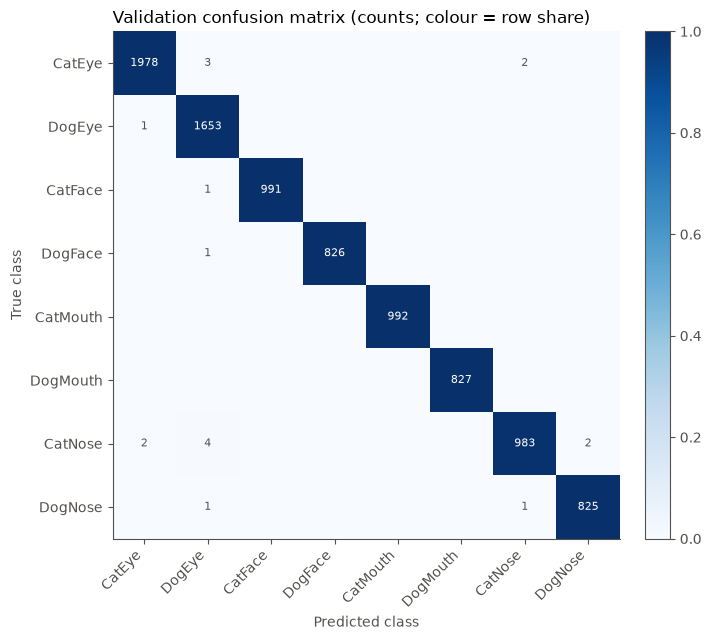

Animal (Cat vs Dog) accuracy:   0.9987
Feature (Eye/Face/...) accuracy: 0.9988
Errors: 18 total - wrong animal only: 7, wrong feature only: 6, both wrong: 5

Most common confusions (true -> predicted):


CatNose -> DogEye     4
CatEye -> DogEye      3
CatNose -> DogNose    2
CatNose -> CatEye     2
CatEye -> CatNose     2
DogNose -> DogEye     1
DogNose -> CatNose    1
CatFace -> DogEye     1
DogFace -> DogEye     1
DogEye -> CatEye      1
Name: count, dtype: int64

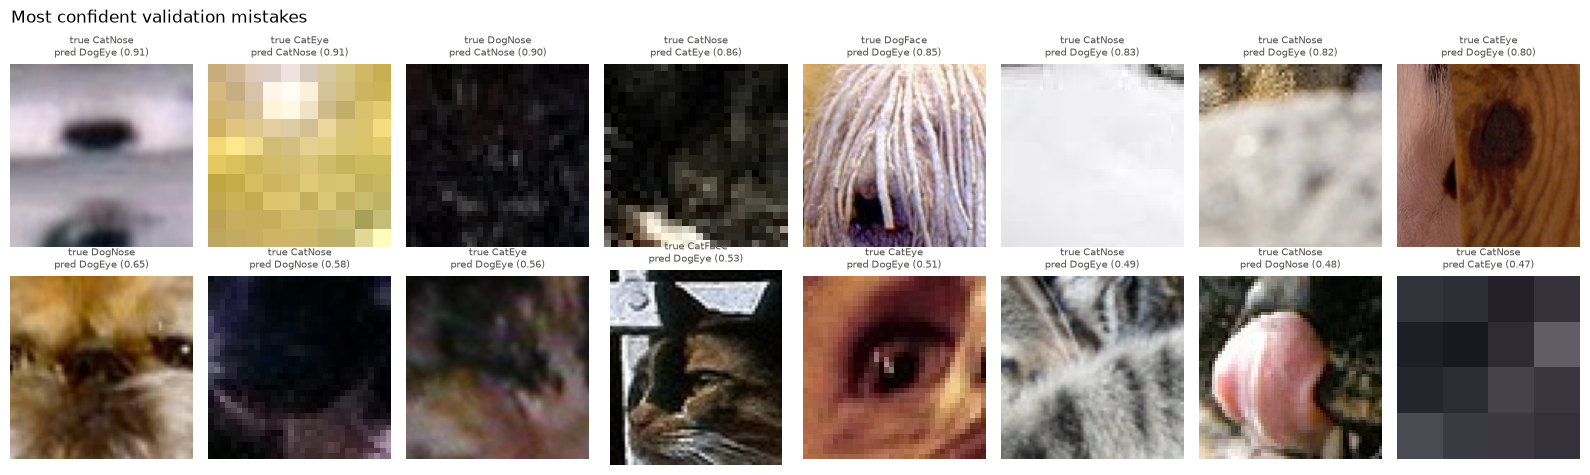

Saved outputs\submission.csv  (29,443 rows)


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth


,train %,test predicted %
class,,
CatEye,21.80,21.33
DogEye,18.19,18.68
CatFace,10.91,10.57
DogFace,9.09,9.46
CatMouth,10.91,11.31
DogMouth,9.10,10.47
CatNose,10.91,9.69
DogNose,9.10,8.49


{
  "arch": "convnext_tiny",
  "img_size": 224,
  "epochs_run": 12,
  "best_epoch": 10,
  "train_minutes": 81.9,
  "val_accuracy": 0.99802,
  "val_loss": 0.09187,
  "val_macro_f1": 0.9982,
  "val_accuracy_no_tta": 0.99835,
  "quick_test": false
}


In [24]:
import math
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# True = tiny check run (2 epochs on a few hundred images, no real submission). Set to False for the real run.
QUICK_TEST = False

TRAIN_CFG = {
    "arch": "convnext_tiny",       # "convnext_tiny" | "efficientnet_v2_s" | "resnet50"
    "pretrained": True,            # start from ImageNet weights (transfer learning)
    "dropout": 0.2,                # dropout before the new output layer
    "epochs": 12,
    "lr": 1e-4,                    # learning rate for the pretrained backbone (AdamW)
    "head_lr_mult": 10,            # the new output layer starts from random weights, so it learns 10x faster
    "weight_decay": 0.05,
    "warmup_epochs": 1,            # linear learning-rate warm-up, then cosine decay
    "label_smoothing": 0.1,
    "use_class_weights": False,    # True = weight the loss by class frequency (training split only)
    "grad_clip": 2.0,              # maximum gradient norm (0 = off)
    "early_stop_patience": 4,      # stop if validation accuracy has not improved for this many epochs
    "tta": True,                   
}
if QUICK_TEST:
    TRAIN_CFG["epochs"] = 2

torch.manual_seed(CFG["seed"])
torch.cuda.manual_seed_all(CFG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"            # mixed precision (float16), roughly 2x faster on GPU
ON_KAGGLE = Path("/kaggle/working").exists()
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU found - the full training will be very slow. On Kaggle: Accelerator -> GPU.")

# Data: the Part B loaders, or small stratified subsets for the quick test.
if QUICK_TEST:
    print(">>> QUICK TEST: small subset, 2 epochs, no real submission file <<<")
    tr_df = train_split.groupby("label").sample(frac=min(1.0, 640 / len(train_split)), random_state=CFG["seed"]).reset_index(drop=True)
    va_df = val_split.groupby("label").sample(frac=min(1.0, 320 / len(val_split)), random_state=CFG["seed"]).reset_index(drop=True)
    te_df = test_df.sample(min(256, len(test_df)), random_state=CFG["seed"]).reset_index(drop=True)
    tr_loader = make_loader(FacialFeatureDataset(tr_df, train_tf), shuffle=True, batch_size=CFG["batch_size"])
    va_loader = make_loader(FacialFeatureDataset(va_df, eval_tf), shuffle=False, batch_size=CFG["batch_size"] * 2)
    te_loader = make_loader(FacialFeatureDataset(te_df, eval_tf, labelled=False), shuffle=False, batch_size=CFG["batch_size"] * 2)
else:
    tr_df, va_df, te_df = train_split, val_split, test_df
    tr_loader, va_loader, te_loader = train_loader, val_loader, test_loader
print(f"Train {len(tr_df):,} | Validation {len(va_df):,} | Test {len(te_df):,} images")

def build_model(arch, num_classes, pretrained=True, dropout=0.2):
    # Returns (model, head) where `head` is the newly created output layer.
    if arch == "convnext_tiny":
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None)
        in_f = model.classifier[2].in_features
        model.classifier[2] = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_f, num_classes))
        head = model.classifier[2]
    elif arch == "efficientnet_v2_s":
        model = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1 if pretrained else None)
        in_f = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_f, num_classes))
        head = model.classifier
    elif arch == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        in_f = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_f, num_classes))
        head = model.fc
    else:
        raise ValueError(f"Unknown arch: {arch}")
    return model, head

try:
    model, head = build_model(TRAIN_CFG["arch"], len(CLASSES), TRAIN_CFG["pretrained"], TRAIN_CFG["dropout"])
except Exception as e:
    raise RuntimeError("Could not create the model (see the error above). If it mentions a download or URL, the "
                       "pretrained weights could not be fetched: on Kaggle turn on Settings -> Internet and re-run.") from e

model = model.to(DEVICE)
if DEVICE.type == "cuda":
    model = model.to(memory_format=torch.channels_last)   # faster convolutions on modern GPUs

n_params = sum(p.numel() for p in model.parameters())
print(f"{TRAIN_CFG['arch']}: {n_params / 1e6:.1f} M parameters ({sum(p.numel() for p in head.parameters()):,} in the new head)")
print("New head:", head)

# Sanity check: output must be (batch, 8) and the loss with the untrained head close to ln(8) = 2.08.
model.eval()
xb, yb = next(iter(va_loader))
with torch.no_grad():
    out = model(xb[:8].to(DEVICE))
print("Input", tuple(xb[:8].shape), "-> output", tuple(out.shape),
      f"| initial loss {F.cross_entropy(out.float(), yb[:8].to(DEVICE)).item():.2f} (expected ~2.1)")
assert out.shape == (min(8, len(xb)), len(CLASSES))

head_ids = {id(p) for p in head.parameters()}
groups = {(is_head, decay): [] for is_head in (False, True) for decay in (False, True)}
for p in model.parameters():
    if p.requires_grad:
        groups[(id(p) in head_ids, p.ndim > 1)].append(p)
optimizer = torch.optim.AdamW([
    {"params": params,
     "lr": TRAIN_CFG["lr"] * (TRAIN_CFG["head_lr_mult"] if is_head else 1),
     "weight_decay": TRAIN_CFG["weight_decay"] if decay else 0.0}
    for (is_head, decay), params in groups.items() if params
])

# Learning-rate schedule (updated every batch): linear warm-up, then cosine decay to 1% of the peak.
steps_per_epoch = len(tr_loader)
total_steps = TRAIN_CFG["epochs"] * steps_per_epoch
warmup_steps = max(1, TRAIN_CFG["warmup_epochs"] * steps_per_epoch)

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# Loss (optional class weights from the training split only).
loss_weights = None
if TRAIN_CFG["use_class_weights"]:
    cnt = np.bincount(tr_df["label"], minlength=len(CLASSES))
    loss_weights = torch.tensor(len(tr_df) / (len(CLASSES) * cnt), dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=loss_weights, label_smoothing=TRAIN_CFG["label_smoothing"])

# Mixed-precision gradient scaler (does nothing on CPU).
try:
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

def to_device(x):
    x = x.to(DEVICE, non_blocking=True)
    return x.to(memory_format=torch.channels_last) if DEVICE.type == "cuda" else x

def train_one_epoch(epoch):
    model.train()
    sum_loss = torch.zeros((), device=DEVICE)
    sum_ce = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)
    n = 0
    t0 = time.time()
    report_every = max(1, len(tr_loader) // 4)
    for step, (x, y) in enumerate(tr_loader, 1):
        x, y = to_device(x), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()
        if TRAIN_CFG["grad_clip"]:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), TRAIN_CFG["grad_clip"])
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        bs = y.size(0)
        n += bs
        sum_loss += loss.detach() * bs
        with torch.no_grad():
            sum_ce += F.cross_entropy(logits.float(), y, reduction="sum")
            correct += (logits.argmax(1) == y).sum()
        if step % report_every == 0 or step == len(tr_loader):
            print(f"  epoch {epoch} step {step}/{len(tr_loader)}  loss {sum_loss.item() / n:.4f}  "
                  f"acc {correct.item() / n:.4f}  {n / (time.time() - t0):.0f} img/s")
    return sum_loss.item() / n, sum_ce.item() / n, correct.item() / n

@torch.no_grad()
def predict(loader, tta=False):
    # Returns (probabilities [N, 8], targets [N]); targets are labels, or image ids for the test loader.
    model.eval()
    probs, targets = [], []
    for x, t in loader:
        x = to_device(x)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2   # mirror image
        probs.append(p.cpu())
        targets.append(t)
    return torch.cat(probs).numpy(), torch.cat(targets).numpy()

def cross_entropy_np(probs, y):
    return float(-np.mean(np.log(np.clip(probs[np.arange(len(y)), y], 1e-7, 1.0))))

# %%
best_path = OUT_DIR / f"best_{TRAIN_CFG['arch']}.pt"
history = []
best_acc, best_epoch, epochs_without_improvement = -1.0, 0, 0
train_start = time.time()

for epoch in range(1, TRAIN_CFG["epochs"] + 1):
    t0 = time.time()
    tr_loss, tr_ce, tr_acc = train_one_epoch(epoch)
    vp, vy = predict(va_loader)
    v_pred = vp.argmax(1)
    row = {
        "epoch": epoch, "lr_backbone": optimizer.param_groups[0]["lr"],
        "train_loss": tr_loss, "train_ce": tr_ce, "train_acc": tr_acc,
        "val_ce": cross_entropy_np(vp, vy), "val_acc": accuracy_score(vy, v_pred),
        "val_macro_f1": f1_score(vy, v_pred, average="macro"), "epoch_time_s": time.time() - t0,
    }
    history.append(row)
    pd.DataFrame(history).to_csv(OUT_DIR / f"history_{TRAIN_CFG['arch']}.csv", index=False)

    improved = row["val_acc"] > best_acc
    if improved:
        best_acc, best_epoch, epochs_without_improvement = row["val_acc"], epoch, 0
        torch.save({"model": model.state_dict(), "epoch": int(epoch), "val_acc": float(best_acc),
                    "cfg": {**CFG, **TRAIN_CFG}}, best_path)
    else:
        epochs_without_improvement += 1

    print(f"Epoch {epoch:2d}/{TRAIN_CFG['epochs']}  train_ce {tr_ce:.4f} acc {tr_acc:.4f} | "
          f"val_ce {row['val_ce']:.4f} acc {row['val_acc']:.4f} f1 {row['val_macro_f1']:.4f} | "
          f"{row['epoch_time_s'] / 60:.1f} min" + ("  <- best, saved" if improved else ""))
    if epoch == 1:
        if DEVICE.type == "cuda":
            print(f"  peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
        print(f"  estimated time for all epochs: {row['epoch_time_s'] * TRAIN_CFG['epochs'] / 60:.0f} min")
    if epochs_without_improvement >= TRAIN_CFG["early_stop_patience"]:
        print(f"Early stopping: no improvement for {epochs_without_improvement} epochs.")
        break

total_min = (time.time() - train_start) / 60
print(f"\nTraining finished in {total_min:.1f} min. Best validation accuracy {best_acc:.4f} at epoch {best_epoch}.")
history_df = pd.DataFrame(history)

# %%
# Learning curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ep = history_df["epoch"]
for ax, (tr_col, va_col, title) in zip(axes, [("train_ce", "val_ce", "Cross-entropy loss"),
                                               ("train_acc", "val_acc", "Accuracy")]):
    ax.plot(ep, history_df[tr_col], color=BLUE, lw=2, marker="o", ms=4, label="train")
    ax.plot(ep, history_df[va_col], color=ORANGE, lw=2, marker="o", ms=4, label="validation")
    ax.axvline(best_epoch, color=INK2, ls="--", lw=1)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Epoch")
    ax.legend(frameon=False)
axes[1].annotate(f"best: {best_acc:.4f} (epoch {best_epoch})", xy=(best_epoch, best_acc), xytext=(-6, -15),
                 textcoords="offset points", fontsize=9, color=INK2, ha="right")
fig.tight_layout()
fig.savefig(OUT_DIR / f"learning_curves_{TRAIN_CFG['arch']}.png", dpi=150, bbox_inches="tight")
plt.show()
display(history_df.round(4))

ckpt = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(ckpt["model"])
print(f"Loaded best checkpoint from epoch {ckpt['epoch']}")

val_probs_plain, val_y = predict(va_loader, tta=False)
val_probs_tta, _ = predict(va_loader, tta=True)

# %%
def summarise(probs, y):
    pred = probs.argmax(1)
    return {"accuracy": accuracy_score(y, pred), "loss": cross_entropy_np(probs, y),
            "macro_f1": f1_score(y, pred, average="macro")}

val_results = pd.DataFrame({"no TTA": summarise(val_probs_plain, val_y), "TTA (flip)": summarise(val_probs_tta, val_y)}).T
display(val_results.round(4))

val_probs = val_probs_tta if TRAIN_CFG["tta"] else val_probs_plain
val_pred = val_probs.argmax(1)

report_df = pd.DataFrame(classification_report(val_y, val_pred, labels=range(len(CLASSES)), target_names=CLASSES,
                                               digits=4, output_dict=True)).T
display(report_df.round(4))
report_df.to_csv(OUT_DIR / f"classification_report_{TRAIN_CFG['arch']}.csv")

# Confusion matrix: rows = true class, columns = predicted class, colour = share of the true class.
cm = confusion_matrix(val_y, val_pred, labels=range(len(CLASSES)))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j]:
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=8,
                    color="white" if cm_norm[i, j] > 0.5 else INK2)
ax.set_title("Validation confusion matrix (counts; colour = row share)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(OUT_DIR / f"confusion_matrix_{TRAIN_CFG['arch']}.png", dpi=150, bbox_inches="tight")
plt.show()

# %%
# What kind of mistakes? Each class = animal (Cat/Dog) + feature (Eye/Face/Mouth/Nose).
names = np.array(CLASSES)
true_c, pred_c = names[val_y], names[val_pred]
animal_ok = np.array([t[:3] == p[:3] for t, p in zip(true_c, pred_c)])
feature_ok = np.array([t[3:] == p[3:] for t, p in zip(true_c, pred_c)])
wrong = true_c != pred_c
print(f"Animal (Cat vs Dog) accuracy:   {animal_ok.mean():.4f}")
print(f"Feature (Eye/Face/...) accuracy: {feature_ok.mean():.4f}")
print(f"Errors: {wrong.sum()} total - wrong animal only: {(wrong & ~animal_ok & feature_ok).sum()}, "
      f"wrong feature only: {(wrong & animal_ok & ~feature_ok).sum()}, both wrong: {(~animal_ok & ~feature_ok).sum()}")
print("\nMost common confusions (true -> predicted):")
display(pd.Series([f"{t} -> {p}" for t, p in zip(true_c[wrong], pred_c[wrong])]).value_counts().head(10).rename("count"))

val_out = pd.DataFrame({"image_id": va_df["image_id"].values, "true": true_c, "pred": pred_c,
                        "confidence": val_probs.max(1), "correct": ~wrong})
val_out = pd.concat([val_out, pd.DataFrame(val_probs, columns=[f"p_{c}" for c in CLASSES])], axis=1)
val_out.to_csv(OUT_DIR / f"val_predictions_{TRAIN_CFG['arch']}.csv", index=False)
np.save(OUT_DIR / f"val_probs_{TRAIN_CFG['arch']}.npy", val_probs)

# The most confident mistakes - often label noise or genuinely ambiguous crops.
worst = val_out[~val_out["correct"]].sort_values("confidence", ascending=False).head(16)
paths = dict(zip(va_df["image_id"], va_df["path"]))
if len(worst):
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), worst.iterrows()):
        img = load_rgb(paths[r["image_id"]])
        if img is not None:
            ax.imshow(img)
        ax.set_title(f"true {r['true']}\npred {r['pred']} ({r['confidence']:.2f})", fontsize=7, color=INK2)
    fig.suptitle("Most confident validation mistakes", x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"misclassified_{TRAIN_CFG['arch']}.png", dpi=150, bbox_inches="tight")
    plt.show()


test_probs, test_ids = predict(te_loader, tta=TRAIN_CFG["tta"])
np.save(OUT_DIR / f"test_probs_{TRAIN_CFG['arch']}.npy", test_probs)
np.save(OUT_DIR / f"test_ids_{TRAIN_CFG['arch']}.npy", test_ids)

pred_df = pd.DataFrame({"image_id": test_ids.astype(int), "class": np.array(CLASSES)[test_probs.argmax(1)]})

# Same columns, ids and order as sample_submission.csv (quick test: only the ids that were predicted).
expected = sample_sub if not QUICK_TEST else sample_sub[sample_sub["image_id"].isin(pred_df["image_id"])]
submission = expected[["image_id"]].merge(pred_df, on="image_id", how="left")[list(sample_sub.columns)]
assert list(submission.columns) == list(sample_sub.columns), "columns differ from sample_submission.csv"
assert len(submission) == len(expected) and submission["image_id"].is_unique, "wrong number of rows / duplicate ids"
assert submission["class"].notna().all(), "some test ids have no prediction"
assert submission["class"].isin(CLASSES).all(), "unknown class name"
assert (submission["image_id"].values == expected["image_id"].values).all(), "row order differs from sample_submission.csv"

sub_name = "submission_QUICK_TEST_DO_NOT_SUBMIT.csv" if QUICK_TEST else "submission.csv"
submission.to_csv(OUT_DIR / sub_name, index=False)
if ON_KAGGLE and not QUICK_TEST:
    submission.to_csv(Path("/kaggle/working") / "submission.csv", index=False)
print(f"Saved {OUT_DIR / sub_name}  ({len(submission):,} rows)")
display(submission.head())

# Sanity check: the predicted class mix should look broadly like the training data.
display(pd.DataFrame({
    "train %": (100 * tr_df["class"].value_counts(normalize=True)).reindex(CLASSES),
    "test predicted %": (100 * submission["class"].value_counts(normalize=True)).reindex(CLASSES).fillna(0),
}).round(2))

# %%
final = "TTA (flip)" if TRAIN_CFG["tta"] else "no TTA"
results = {
    "arch": TRAIN_CFG["arch"], "img_size": CFG["img_size"], "epochs_run": int(history_df["epoch"].max()),
    "best_epoch": int(best_epoch), "train_minutes": round(total_min, 1),
    "val_accuracy": round(float(val_results.loc[final, "accuracy"]), 5),
    "val_loss": round(float(val_results.loc[final, "loss"]), 5),
    "val_macro_f1": round(float(val_results.loc[final, "macro_f1"]), 5),
    "val_accuracy_no_tta": round(float(val_results.loc["no TTA", "accuracy"]), 5),
    "quick_test": QUICK_TEST, "config": {**CFG, **TRAIN_CFG},
}
with open(OUT_DIR / f"results_{TRAIN_CFG['arch']}.json", "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps({k: v for k, v in results.items() if k != "config"}, indent=2))
if QUICK_TEST:
    print("\nQuick test finished without errors. Set QUICK_TEST = False at the top of Part C and run Part C again.")

Median image properties (train vs test):


C:\Users\User\AppData\Local\Temp\ipykernel_14984\3090606209.py:15: DtypeWarning: Columns (1: class) have mixed types. Specify dtype option on import or set low_memory=False.
  stats = pd.read_csv(OUT_DIR / "image_stats.csv")               # saved by Part A


split,test,train
width,82.00,84.00
height,80.00,80.00
aspect,1.00,1.00
file_kb,4.11,4.23
blur,1347.39,1369.27


Colour modes (% of each split):


split,test,train
mode,,
RGB,100.0,100.0


Mean confidence:        validation 0.9153 | test 0.9104
Confidence below 0.90:  validation 0.48% | test 3.61%
Class mix (%):


,train (true),validation (predicted),test (predicted)
CatEye,21.80,21.79,21.33
DogEye,18.19,18.29,18.68
CatFace,10.91,10.90,10.57
DogFace,9.09,9.08,9.46
CatMouth,10.91,10.91,11.31
DogMouth,9.10,9.09,10.47
CatNose,10.91,10.84,9.69
DogNose,9.10,9.09,8.49


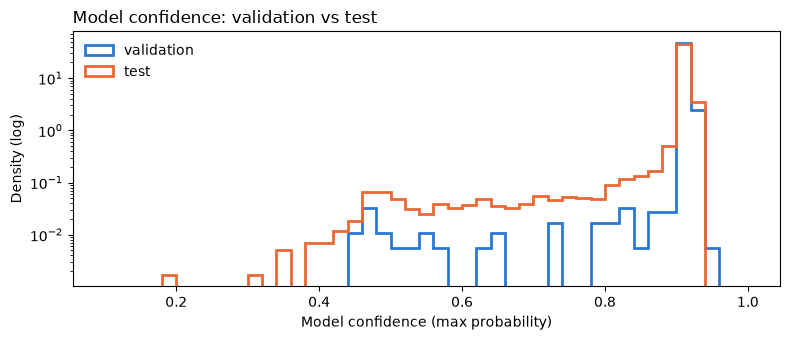

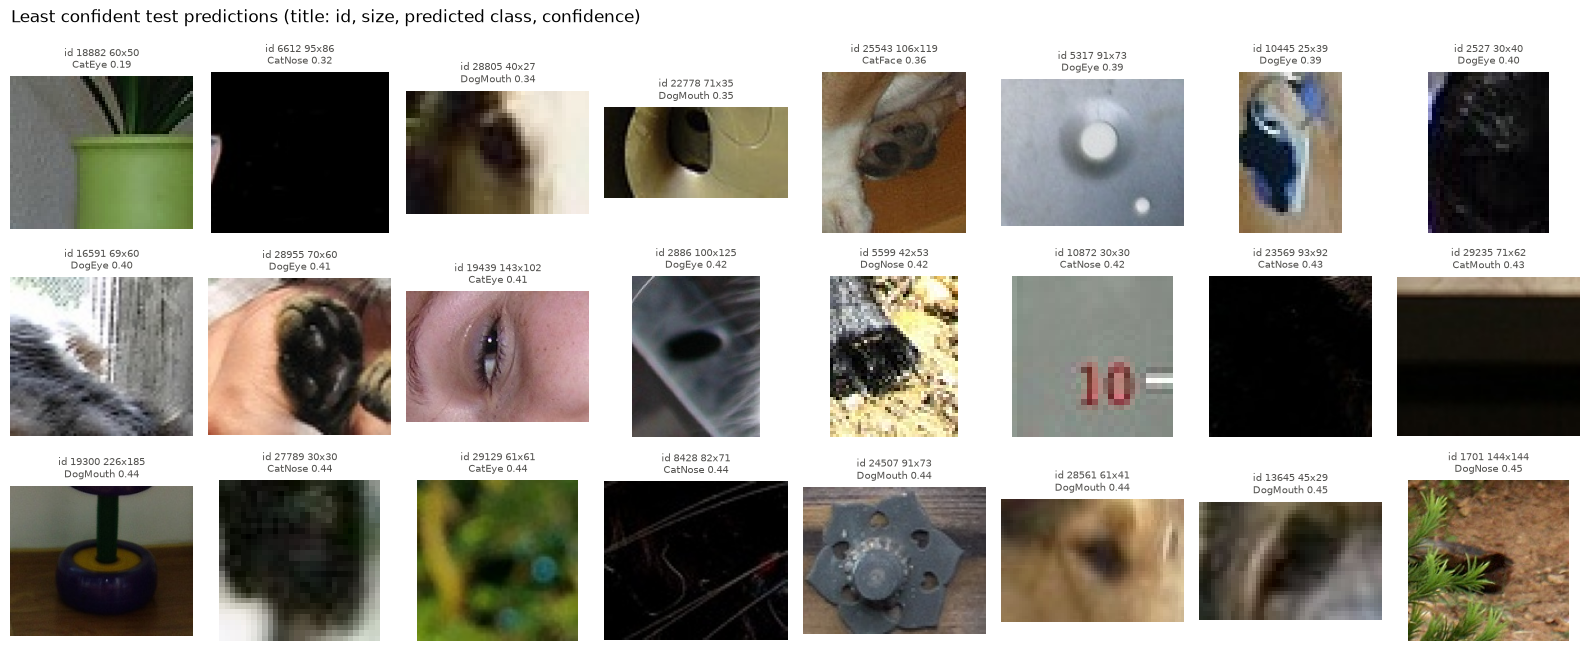

In [2]:
# Part D - Why is the leaderboard score lower than validation? (standalone: loads the saved files, no re-training)
# Uses only image properties and the model's own confidence: no test labels are used or guessed.
# (Don't hand-correct any test predictions - manual labelling is against the competition rules.)
import os, re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path(os.environ.get("DATA_DIR", r"C:\Users\User\Documents\Data_Enginerring_AI\ENGE707-2026-S2-Facial-Feature-Classification-Challenge\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"))
OUT_DIR = Path(os.environ.get("OUT_DIR", "outputs"))
ARCH = "convnext_tiny"
CLASSES = ["CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose"]
BLUE, ORANGE, INK2 = "#2a78d6", "#eb6834", "#52514e"

stats = pd.read_csv(OUT_DIR / "image_stats.csv")               # saved by Part A
val_pred = pd.read_csv(OUT_DIR / f"val_predictions_{ARCH}.csv") # saved by Part C
val_probs = val_pred[[f"p_{c}" for c in CLASSES]].to_numpy()
test_probs = np.load(OUT_DIR / f"test_probs_{ARCH}.npy")
test_ids = np.load(OUT_DIR / f"test_ids_{ARCH}.npy")
splits = pd.read_csv(OUT_DIR / "splits.csv")                     # saved by Part B
train_classes = splits.loc[~splits["is_val"], "class"]

ok_s = stats[stats["ok"].astype(bool)]
print("Median image properties (train vs test):")
display(ok_s.groupby("split")[["width", "height", "aspect", "file_kb", "blur"]].median().T.round(2))
print("Colour modes (% of each split):")
display((100 * pd.crosstab(ok_s["mode"], ok_s["split"], normalize="columns")).round(2))

val_conf, test_conf = val_probs.max(1), test_probs.max(1)
print(f"Mean confidence:        validation {val_conf.mean():.4f} | test {test_conf.mean():.4f}")
print(f"Confidence below 0.90:  validation {np.mean(val_conf < 0.9):.2%} | test {np.mean(test_conf < 0.9):.2%}")

print("Class mix (%):")
display(pd.DataFrame({
    "train (true)": 100 * train_classes.value_counts(normalize=True),
    "validation (predicted)": 100 * pd.Series(np.array(CLASSES)[val_probs.argmax(1)]).value_counts(normalize=True),
    "test (predicted)": 100 * pd.Series(np.array(CLASSES)[test_probs.argmax(1)]).value_counts(normalize=True),
}).reindex(CLASSES).fillna(0).round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0.1, 1, 46)
ax.hist(val_conf, bins=bins, density=True, histtype="step", lw=2, color=BLUE, label="validation")
ax.hist(test_conf, bins=bins, density=True, histtype="step", lw=2, color=ORANGE, label="test")
ax.set_yscale("log"); ax.set_xlabel("Model confidence (max probability)"); ax.set_ylabel("Density (log)")
ax.set_title("Model confidence: validation vs test", loc="left"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT_DIR / "confidence_val_vs_test.png", dpi=150, bbox_inches="tight"); plt.show()

# The 24 test images the model is least sure about - what do they look like?
root = next(DATA_DIR.rglob("sample_submission.csv")).parent
test_files = {}
for p in root.rglob("*"):
    folders = [s.lower() for s in p.relative_to(root).parts[:-1]]
    m = re.search(r"(\d+)$", p.stem)
    if p.is_file() and m and any("test" in s for s in folders):
        test_files[int(m.group(1))] = p
low = np.argsort(test_conf)[:24]
fig, axes = plt.subplots(3, 8, figsize=(16, 6.6))
for ax, i in zip(axes.ravel(), low):
    tid = int(test_ids[i])
    try:
        with Image.open(test_files[tid]) as im:
            img = im.convert("RGB")
        ax.imshow(img)
        size = f"{img.size[0]}x{img.size[1]}"
    except Exception:
        size = "?"
    ax.set_title(f"id {tid} {size}\n{CLASSES[test_probs[i].argmax()]} {test_conf[i]:.2f}", fontsize=7, color=INK2)
    ax.axis("off")
fig.suptitle("Least confident test predictions (title: id, size, predicted class, confidence)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(OUT_DIR / "least_confident_test.png", dpi=150, bbox_inches="tight"); plt.show()

GPU: NVIDIA GeForce RTX 3060
Train 54,552 | Validation 9,093 | Test 29,443
Train transform: Compose(
    RandomLowRes(p=0.25, side=10-40)
    RandomDarken(p=0.15, factor=0.15-0.5)
    RandomBlur(p=0.15, radius<=1.5)
    ColorJitter(brightness=(0.7, 1.3), contrast=(0.7, 1.3), saturation=(0.7, 1.3), hue=(-0.03, 0.03))
    RandomGrayscale(p=0.05)
    RandomHorizontalFlip(p=0.5)
    RandomAffine(degrees=[-15.0, 15.0], translate=(0.08, 0.08), scale=(0.85, 1.15), fill=(124, 116, 104))
    ResizePad(size=224)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    RandomErasing(p=0.25, scale=(0.02, 0.15), ratio=(0.3, 3.3), value=0, inplace=False)
)
First batch loaded in 11.8s with 4 workers


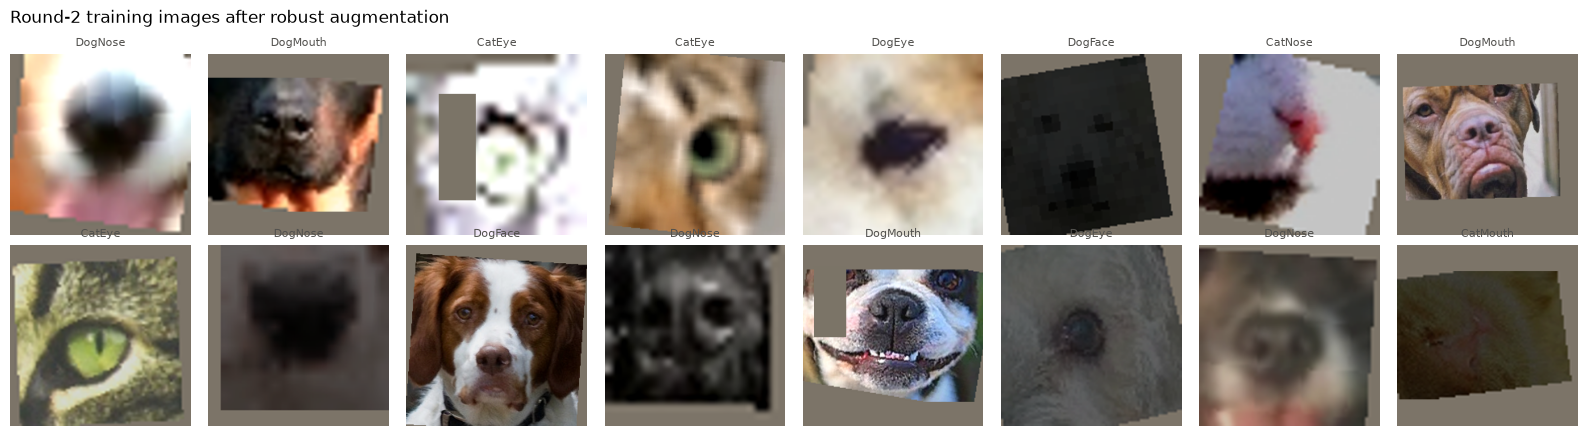

convnext_tiny ready: 27.8 M parameters, 852 steps/epoch
  epoch 1 step 213/852  ce 1.3506  acc 0.5414  280 img/s
  epoch 1 step 426/852  ce 0.8179  acc 0.7419  280 img/s
  epoch 1 step 639/852  ce 0.6126  acc 0.8156  281 img/s
  epoch 1 step 852/852  ce 0.5054  acc 0.8537  281 img/s
Epoch  1/12  train_ce 0.5054 acc 0.8537 | val_ce 0.1181 acc 0.9883 | 3.7 min  <- saved
  estimated time for all epochs: 44 min
  epoch 2 step 213/852  ce 0.1773  acc 0.9699  279 img/s
  epoch 2 step 426/852  ce 0.1703  acc 0.9726  277 img/s
  epoch 2 step 639/852  ce 0.1666  acc 0.9737  278 img/s
  epoch 2 step 852/852  ce 0.1638  acc 0.9746  279 img/s
Epoch  2/12  train_ce 0.1638 acc 0.9746 | val_ce 0.1012 acc 0.9933 | 3.6 min  <- saved
  epoch 3 step 213/852  ce 0.1431  acc 0.9830  279 img/s
  epoch 3 step 426/852  ce 0.1449  acc 0.9821  280 img/s
  epoch 3 step 639/852  ce 0.1431  acc 0.9827  280 img/s
  epoch 3 step 852/852  ce 0.1427  acc 0.9826  281 img/s
Epoch  3/12  train_ce 0.1427 acc 0.9826 | val_

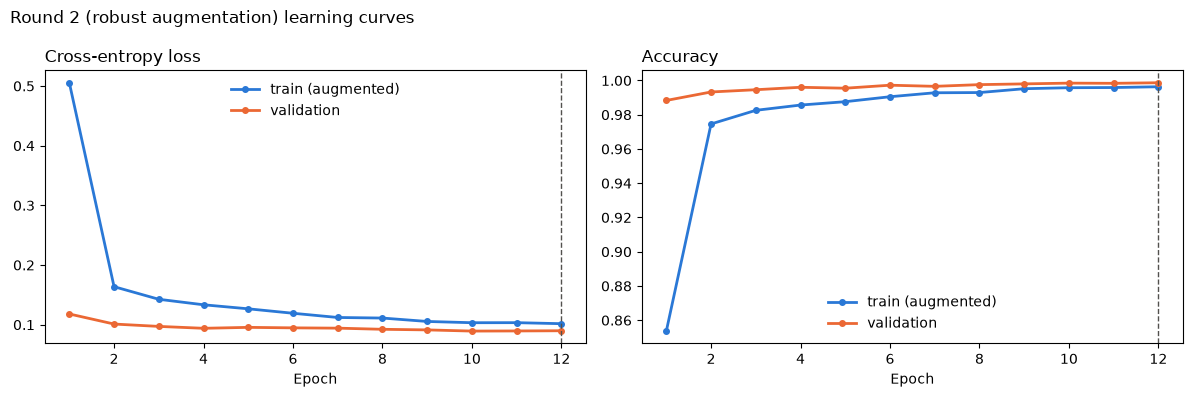

,clean,lowres,dark,blur,mean (degraded)
round 1,99.80,93.29,99.62,98.46,97.12
round 2 (robust),99.86,99.54,99.82,99.46,99.61


Saved outputs\submission_convnext_tiny_robust.csv (29,443 rows)
Round 1 and round 2 agree on 98.16% of test images
Saved outputs\submission_ensemble.csv (29,443 rows)


In [4]:
# Part E (round 2: robust training + ensemble). Paste at the END of your notebook.
# Standalone: after a restart run only these cells. Needs robust_data.py in the same folder.

# %% [markdown]
# # Part E — Round 2: robustness training and ensemble (Task 6 improvement)
#
# **Why:** the first model scored 99.79% on validation but 96.62% on the Kaggle leaderboard. The diagnostic (Part D)
# showed the test set has ~7× more low-confidence images than validation (3.61% vs 0.48%) — very dark, tiny/pixelated,
# blurry or barely-recognisable crops — while image sizes and colour modes match.
#
# **What changes in round 2:**
# 1. Augmentation that simulates those conditions (random pixelation, darkening, blur, greyscale, stronger
#    rotation/shift/zoom, random erasing) — see `robust_data.py`.
# 2. Images load in parallel worker processes (the data code is in `robust_data.py`, which Windows workers can import).
# 3. A **stress test**: both models are evaluated on validation images that are deliberately pixelated, darkened or
#    blurred, as an offline estimate of robustness.
# 4. An **ensemble**: the average of the round-1 and round-2 probabilities.
#
# **These cells are standalone** — after a restart you only need to run Part E (not Parts A–C). `robust_data.py`
# must be in the same folder as this notebook. Run with `QUICK_TEST = True` first, then `False`.
#
# **Your justification / observations (write your own):** _why these augmentations, and what the results show_

# %%
import os, re, sys, json, math, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from sklearn.metrics import accuracy_score, f1_score

sys.path.insert(0, str(Path.cwd()))
import importlib, robust_data
importlib.reload(robust_data)   # picks up edits to robust_data.py without restarting
from robust_data import FacialFeatureDataset, build_transforms, make_loader, IMAGENET_MEAN, IMAGENET_STD

QUICK_TEST = False        # True = short check run. Then set False for the real run.

DATA_DIR = Path(os.environ.get("DATA_DIR", r"C:\Users\User\Documents\Data_Enginerring_AI\ENGE707-2026-S2-Facial-Feature-Classification-Challenge\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"))
OUT_DIR = Path(os.environ.get("OUT_DIR", "outputs"))
CLASSES = ["CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose"]
BLUE, ORANGE, INK2 = "#2a78d6", "#eb6834", "#52514e"

R2 = {
    "run_name": "convnext_tiny_robust",
    "round1_name": "convnext_tiny",     # files from the first run: best_convnext_tiny.pt, test_probs_convnext_tiny.npy
    "arch": "convnext_tiny",
    "img_size": 224,
    "seed": 7,                          # different seed from round 1 -> more diverse ensemble
    "dropout": 0.2,
    "epochs": 12,
    "batch_size": 64,
    "lr": 1e-4, "head_lr_mult": 10, "weight_decay": 0.05, "warmup_epochs": 1,
    "label_smoothing": 0.1, "grad_clip": 2.0, "early_stop_patience": 5,
    "num_workers": min(4, os.cpu_count() or 1),   # parallel image loading (works on Windows via robust_data.py)
}
if QUICK_TEST:
    R2["epochs"] = 2

random.seed(R2["seed"]); np.random.seed(R2["seed"]); torch.manual_seed(R2["seed"]); torch.cuda.manual_seed_all(R2["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU found - this will be very slow.")

# ---- Data: the same train/validation split as before (outputs/splits.csv from Part B) ----
root = next(DATA_DIR.rglob("sample_submission.csv")).parent
splits = pd.read_csv(OUT_DIR / "splits.csv")
splits["path"] = splits["relpath"].map(lambda r: root / str(r).replace("\\", "/"))
sample_sub = pd.read_csv(root / "sample_submission.csv")

test_files = {}
for p in root.rglob("*"):
    folders = [s.lower() for s in p.relative_to(root).parts[:-1]]
    m = re.search(r"(\d+)$", p.stem)
    if p.is_file() and m and any("test" in s for s in folders):
        test_files[int(m.group(1))] = p
test_df = sample_sub[["image_id"]].assign(path=sample_sub["image_id"].map(test_files))
assert test_df["path"].notna().all(), "some test images were not found"

tr_df = splits[~splits["is_val"]].reset_index(drop=True)
va_df = splits[splits["is_val"]].reset_index(drop=True)
te_df = test_df
if QUICK_TEST:
    print(">>> QUICK TEST: small subset, 2 epochs <<<")
    tr_df = tr_df.groupby("label").sample(frac=min(1.0, 640 / len(tr_df)), random_state=R2["seed"]).reset_index(drop=True)
    va_df = va_df.groupby("label").sample(frac=min(1.0, 320 / len(va_df)), random_state=R2["seed"]).reset_index(drop=True)
    te_df = test_df.sample(min(256, len(test_df)), random_state=R2["seed"]).reset_index(drop=True)
print(f"Train {len(tr_df):,} | Validation {len(va_df):,} | Test {len(te_df):,}")

S, NW, PIN = R2["img_size"], R2["num_workers"], DEVICE.type == "cuda"
def loader(df, mode, labelled=True, shuffle=False, bs=None):
    ds = FacialFeatureDataset(df["path"], df["image_id"], df["label"] if labelled else None, build_transforms(S, mode), S)
    return make_loader(ds, shuffle, bs or R2["batch_size"] * 2, NW, seed=R2["seed"], pin_memory=PIN, persistent=shuffle)

tr_loader = loader(tr_df, "train", shuffle=True, bs=R2["batch_size"])
va_loader = loader(va_df, "eval")
te_loader = loader(te_df, "eval", labelled=False)
print("Train transform:", build_transforms(S, "train"))

# Preview: 16 training images after the robust augmentation.
def denorm(x):
    return (x * torch.tensor(IMAGENET_STD).view(3, 1, 1) + torch.tensor(IMAGENET_MEAN).view(3, 1, 1)).clamp(0, 1).permute(1, 2, 0).numpy()
t0 = time.time()
xb, yb = next(iter(tr_loader))
print(f"First batch loaded in {time.time() - t0:.1f}s with {NW} workers")
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, x, y in zip(axes.ravel(), xb[:16], yb[:16]):
    ax.imshow(denorm(x)); ax.axis("off"); ax.set_title(CLASSES[int(y)], fontsize=8, color=INK2)
fig.suptitle("Round-2 training images after robust augmentation", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(OUT_DIR / "augmentation_preview_robust.png", dpi=150, bbox_inches="tight"); plt.show()

# %%
# ---- Model, optimiser, schedule (same recipe as round 1) ----
def build_model(arch, num_classes, pretrained=True, dropout=0.2):
    if arch == "convnext_tiny":
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None)
        model.classifier[2] = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier[2].in_features, num_classes))
        head = model.classifier[2]
    elif arch == "efficientnet_v2_s":
        model = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1 if pretrained else None)
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier[1].in_features, num_classes))
        head = model.classifier
    else:
        raise ValueError(arch)
    return model, head

def prepare(m):
    m = m.to(DEVICE)
    return m.to(memory_format=torch.channels_last) if DEVICE.type == "cuda" else m

model, head = build_model(R2["arch"], len(CLASSES), True, R2["dropout"])
model = prepare(model)

head_ids = {id(p) for p in head.parameters()}
groups = {(h, d): [] for h in (False, True) for d in (False, True)}
for p in model.parameters():
    if p.requires_grad:
        groups[(id(p) in head_ids, p.ndim > 1)].append(p)
optimizer = torch.optim.AdamW([
    {"params": ps, "lr": R2["lr"] * (R2["head_lr_mult"] if h else 1), "weight_decay": R2["weight_decay"] if d else 0.0}
    for (h, d), ps in groups.items() if ps
])
steps_per_epoch = len(tr_loader)
total_steps = R2["epochs"] * steps_per_epoch
warmup_steps = max(1, R2["warmup_epochs"] * steps_per_epoch)
def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * progress))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
criterion = nn.CrossEntropyLoss(label_smoothing=R2["label_smoothing"])
try:
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

def to_device(x):
    x = x.to(DEVICE, non_blocking=True)
    return x.to(memory_format=torch.channels_last) if DEVICE.type == "cuda" else x

def train_one_epoch(epoch):
    model.train()
    sum_ce = torch.zeros((), device=DEVICE); correct = torch.zeros((), device=DEVICE); n = 0
    t0 = time.time(); report_every = max(1, len(tr_loader) // 4)
    for step, (x, y) in enumerate(tr_loader, 1):
        x, y = to_device(x), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), R2["grad_clip"])
        scaler.step(optimizer); scaler.update(); scheduler.step()
        n += y.size(0)
        with torch.no_grad():
            sum_ce += F.cross_entropy(logits.float(), y, reduction="sum")
            correct += (logits.argmax(1) == y).sum()
        if step % report_every == 0 or step == len(tr_loader):
            print(f"  epoch {epoch} step {step}/{len(tr_loader)}  ce {sum_ce.item() / n:.4f}  acc {correct.item() / n:.4f}  "
                  f"{n / (time.time() - t0):.0f} img/s")
    return sum_ce.item() / n, correct.item() / n

@torch.no_grad()
def predict(m, loader, tta=False):
    m.eval(); probs, targets = [], []
    for x, t in loader:
        x = to_device(x)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            p = m(x).float().softmax(1)
            if tta:
                p = (p + m(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        probs.append(p.cpu()); targets.append(t)
    return torch.cat(probs).numpy(), torch.cat(targets).numpy()

def cross_entropy_np(probs, y):
    return float(-np.mean(np.log(np.clip(probs[np.arange(len(y)), y], 1e-7, 1.0))))

print(f"{R2['arch']} ready: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters, {steps_per_epoch} steps/epoch")

# %%
# ---- Training ----
best_path = OUT_DIR / f"best_{R2['run_name']}.pt"
history, best_acc, best_epoch, bad = [], -1.0, 0, 0
train_start = time.time()
for epoch in range(1, R2["epochs"] + 1):
    t0 = time.time()
    tr_ce, tr_acc = train_one_epoch(epoch)
    vp, vy = predict(model, va_loader)
    row = {"epoch": epoch, "train_ce": tr_ce, "train_acc": tr_acc, "val_ce": cross_entropy_np(vp, vy),
           "val_acc": accuracy_score(vy, vp.argmax(1)), "val_macro_f1": f1_score(vy, vp.argmax(1), average="macro"),
           "epoch_time_s": time.time() - t0}
    history.append(row)
    pd.DataFrame(history).to_csv(OUT_DIR / f"history_{R2['run_name']}.csv", index=False)
    # ">=" keeps the later epoch on ties: validation accuracy is near its ceiling, and later epochs have seen
    # more of the robust augmentation.
    improved = row["val_acc"] >= best_acc
    if improved:
        best_acc, best_epoch, bad = row["val_acc"], epoch, 0
        torch.save({"model": model.state_dict(), "epoch": int(epoch), "val_acc": float(best_acc), "cfg": R2}, best_path)
    else:
        bad += 1
    print(f"Epoch {epoch:2d}/{R2['epochs']}  train_ce {tr_ce:.4f} acc {tr_acc:.4f} | val_ce {row['val_ce']:.4f} "
          f"acc {row['val_acc']:.4f} | {row['epoch_time_s'] / 60:.1f} min" + ("  <- saved" if improved else ""))
    if epoch == 1:
        print(f"  estimated time for all epochs: {row['epoch_time_s'] * R2['epochs'] / 60:.0f} min")
    if bad >= R2["early_stop_patience"]:
        print("Early stopping."); break
total_min = (time.time() - train_start) / 60
history_df = pd.DataFrame(history)
print(f"\nDone in {total_min:.1f} min. Best validation accuracy {best_acc:.4f} (epoch {best_epoch}).")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (a, b, title) in zip(axes, [("train_ce", "val_ce", "Cross-entropy loss"), ("train_acc", "val_acc", "Accuracy")]):
    ax.plot(history_df["epoch"], history_df[a], color=BLUE, lw=2, marker="o", ms=4, label="train (augmented)")
    ax.plot(history_df["epoch"], history_df[b], color=ORANGE, lw=2, marker="o", ms=4, label="validation")
    ax.axvline(best_epoch, color=INK2, ls="--", lw=1); ax.set_title(title, loc="left"); ax.set_xlabel("Epoch"); ax.legend(frameon=False)
fig.suptitle("Round 2 (robust augmentation) learning curves", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(OUT_DIR / f"learning_curves_{R2['run_name']}.png", dpi=150, bbox_inches="tight"); plt.show()

# %% [markdown]
# ### Robustness stress test: round 1 vs round 2 on deliberately degraded validation images

# %%
model.load_state_dict(torch.load(best_path, map_location=DEVICE)["model"])

models_to_test = {"round 2 (robust)": model}
r1_path = OUT_DIR / f"best_{R2['round1_name']}.pt"
if r1_path.exists():
    model_r1, _ = build_model(R2["arch"], len(CLASSES), pretrained=False, dropout=R2["dropout"])
    model_r1.load_state_dict(torch.load(r1_path, map_location=DEVICE)["model"])
    models_to_test = {"round 1": prepare(model_r1), **models_to_test}
else:
    print(f"{r1_path} not found - only round 2 is tested")

rows = {}
for cond in ["eval", "lowres", "dark", "blur"]:
    ld = loader(va_df, cond)
    for name, m in models_to_test.items():
        p, y = predict(m, ld, tta=True)
        rows.setdefault(name, {})["clean" if cond == "eval" else cond] = accuracy_score(y, p.argmax(1))
stress = pd.DataFrame(rows).T
stress["mean (degraded)"] = stress[["lowres", "dark", "blur"]].mean(axis=1)
display((100 * stress).round(2))
stress.to_csv(OUT_DIR / "stress_test_round1_vs_round2.csv")

# %% [markdown]
# ### Test predictions, round-2 submission and ensemble submission

# %%
def check_and_save(pred_classes, ids, filename):
    pred_df = pd.DataFrame({"image_id": ids.astype(int), "class": pred_classes})
    expected = sample_sub if not QUICK_TEST else sample_sub[sample_sub["image_id"].isin(pred_df["image_id"])]
    sub = expected[["image_id"]].merge(pred_df, on="image_id", how="left")[list(sample_sub.columns)]
    assert len(sub) == len(expected) and sub["image_id"].is_unique and sub["class"].notna().all()
    assert sub["class"].isin(CLASSES).all() and (sub["image_id"].values == expected["image_id"].values).all()
    name = filename.replace(".csv", "_QUICK_TEST_DO_NOT_SUBMIT.csv") if QUICK_TEST else filename
    sub.to_csv(OUT_DIR / name, index=False)
    print(f"Saved {OUT_DIR / name} ({len(sub):,} rows)")
    return sub

test_probs_r2, test_ids_r2 = predict(model, te_loader, tta=True)
np.save(OUT_DIR / f"test_probs_{R2['run_name']}.npy", test_probs_r2)
np.save(OUT_DIR / f"test_ids_{R2['run_name']}.npy", test_ids_r2)
sub_r2 = check_and_save(np.array(CLASSES)[test_probs_r2.argmax(1)], test_ids_r2, f"submission_{R2['run_name']}.csv")

# Ensemble: average the class probabilities of round 1 and round 2 (aligned by image_id).
r1_probs_file = OUT_DIR / f"test_probs_{R2['round1_name']}.npy"
if r1_probs_file.exists():
    p1 = pd.DataFrame(np.load(r1_probs_file), index=np.load(OUT_DIR / f"test_ids_{R2['round1_name']}.npy").astype(int))
    p1 = p1.reindex(test_ids_r2.astype(int))
    if p1.isna().any().any():
        print("Round-1 probabilities don't cover these test ids (expected in quick-test mode) - ensemble skipped.")
    else:
        ens = (p1.to_numpy() + test_probs_r2) / 2
        np.save(OUT_DIR / "test_probs_ensemble.npy", ens)
        agree = np.mean(p1.to_numpy().argmax(1) == test_probs_r2.argmax(1))
        print(f"Round 1 and round 2 agree on {agree:.2%} of test images")
        sub_ens = check_and_save(np.array(CLASSES)[ens.argmax(1)], test_ids_r2, "submission_ensemble.csv")
else:
    print(f"{r1_probs_file} not found - ensemble skipped")

with open(OUT_DIR / f"results_{R2['run_name']}.json", "w") as f:
    json.dump({"run": R2["run_name"], "best_epoch": int(best_epoch), "val_acc": float(best_acc),
               "train_minutes": round(total_min, 1),
               "stress_test": {k: {c: float(v) for c, v in r.items()} for k, r in stress.T.to_dict().items()},
               "quick_test": QUICK_TEST, "config": R2}, f, indent=2)
if QUICK_TEST:
    print("\nQuick test finished without errors. Set QUICK_TEST = False in the first Part E cell and run Part E again.")

# %% [markdown]
# ## Round 2 results
#
# | Submission | Validation acc | Kaggle public score |
# |---|---|---|
# | Round 1 (`submission.csv`) | 99.79% | 96.62% |
# | Round 2 robust (`submission_convnext_tiny_robust.csv`) | _fill in_ | _fill in_ |
# | Ensemble (`submission_ensemble.csv`) | – | _fill in_ |
#
# **Your analysis (write your own):** _what the stress test and leaderboard scores show_